In [1]:
import os
import numpy as np
import awkward as ak
import h5py
from utils.utilities import Get_ak_from_hdf5
from utils.plotting_utils import plot_tracks_polar, get_pv_res
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Rectangle, Ellipse
from scipy.spatial.distance import cdist, pdist
from scipy.spatial.distance import cosine as sp_cos
import scipy

from sklearn.preprocessing import normalize
from torch_geometric.utils import dense_to_sparse, to_edge_index, to_torch_coo_tensor
import torch
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
import pandas as pd
from torch_geometric.utils import to_dense_adj


In [2]:
fileName = "/data/home/sakar/ML_dir/pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks.hdf5"
#fileName = "/data/home/sakar/ML_dir/pv_HLT1CPU_MinBiasMagUp_AllFiles__validPVs_2tracks.hdf5"
file = h5py.File(fileName, "r")

In [3]:
poca_x = Get_ak_from_hdf5(file, "poca_x")
poca_y = Get_ak_from_hdf5(file, "poca_y")
poca_z = Get_ak_from_hdf5(file, "poca_z")
poca_A = Get_ak_from_hdf5(file, "poca_A")
poca_B = Get_ak_from_hdf5(file, "poca_B")
poca_C = Get_ak_from_hdf5(file, "poca_C")
poca_D = Get_ak_from_hdf5(file, "poca_D")
poca_E = Get_ak_from_hdf5(file, "poca_E")
poca_F = Get_ak_from_hdf5(file, "poca_F")

major_axis_x  = Get_ak_from_hdf5(file, "major_axis_x")
major_axis_y  = Get_ak_from_hdf5(file, "major_axis_y")
major_axis_z  = Get_ak_from_hdf5(file, "major_axis_z")

minor_axis1_x  = Get_ak_from_hdf5(file, "minor_axis1_x")
minor_axis1_y  = Get_ak_from_hdf5(file, "minor_axis1_y")
minor_axis1_z  = Get_ak_from_hdf5(file, "minor_axis1_z")

minor_axis2_x  = Get_ak_from_hdf5(file, "minor_axis2_x")
minor_axis2_y  = Get_ak_from_hdf5(file, "minor_axis2_y")
minor_axis2_z  = Get_ak_from_hdf5(file, "minor_axis2_z")

recon_tx  = Get_ak_from_hdf5(file, "recon_tx")
recon_ty  = Get_ak_from_hdf5(file, "recon_ty")


poca_sigma_x = 1./np.sqrt(poca_A)
poca_sigma_y = 1./np.sqrt(poca_B)
poca_sigma_z = 1./np.sqrt(poca_C)


In [4]:
recon_pv_key = Get_ak_from_hdf5(file, "recon_pv_key")
pv_key = Get_ak_from_hdf5(file, "pv_key")
pv_x  = Get_ak_from_hdf5(file, "pv_x")
pv_y  = Get_ak_from_hdf5(file, "pv_y")
pv_z  = Get_ak_from_hdf5(file, "pv_z")
pv_n  = Get_ak_from_hdf5(file, "pv_ntracks")
pv_cat  = Get_ak_from_hdf5(file, "pv_cat")

In [5]:
pv_res     = get_pv_res(pv_n)

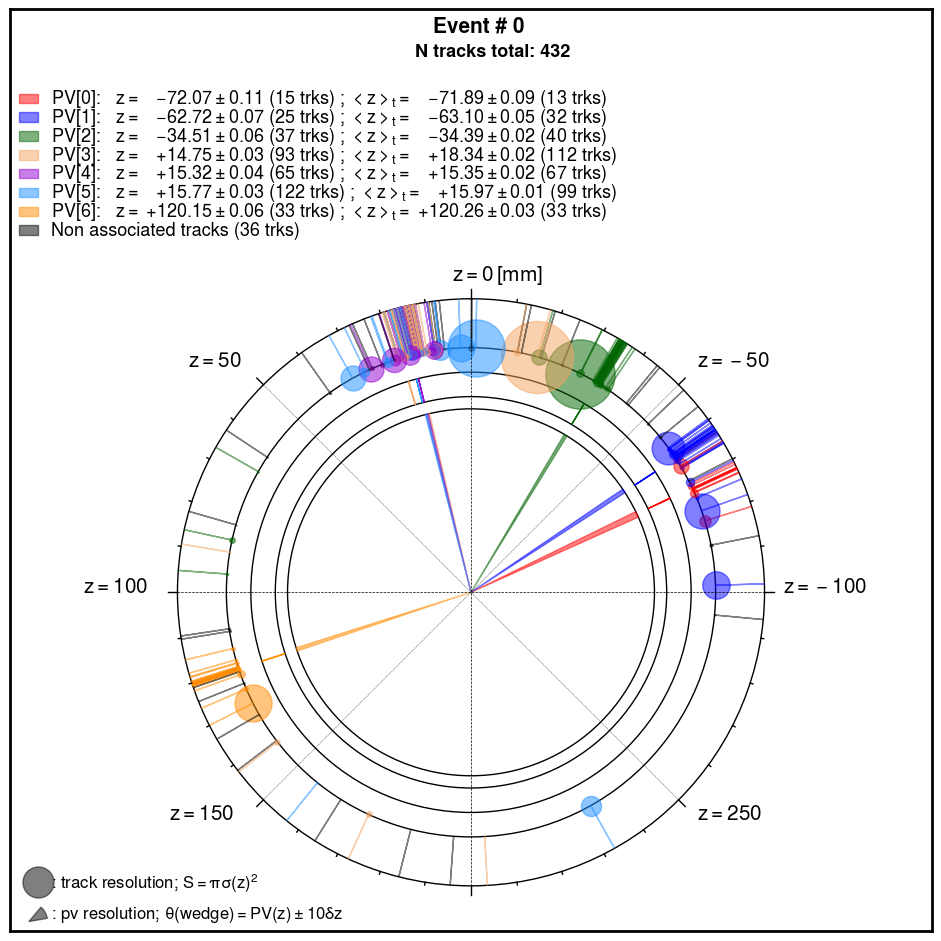

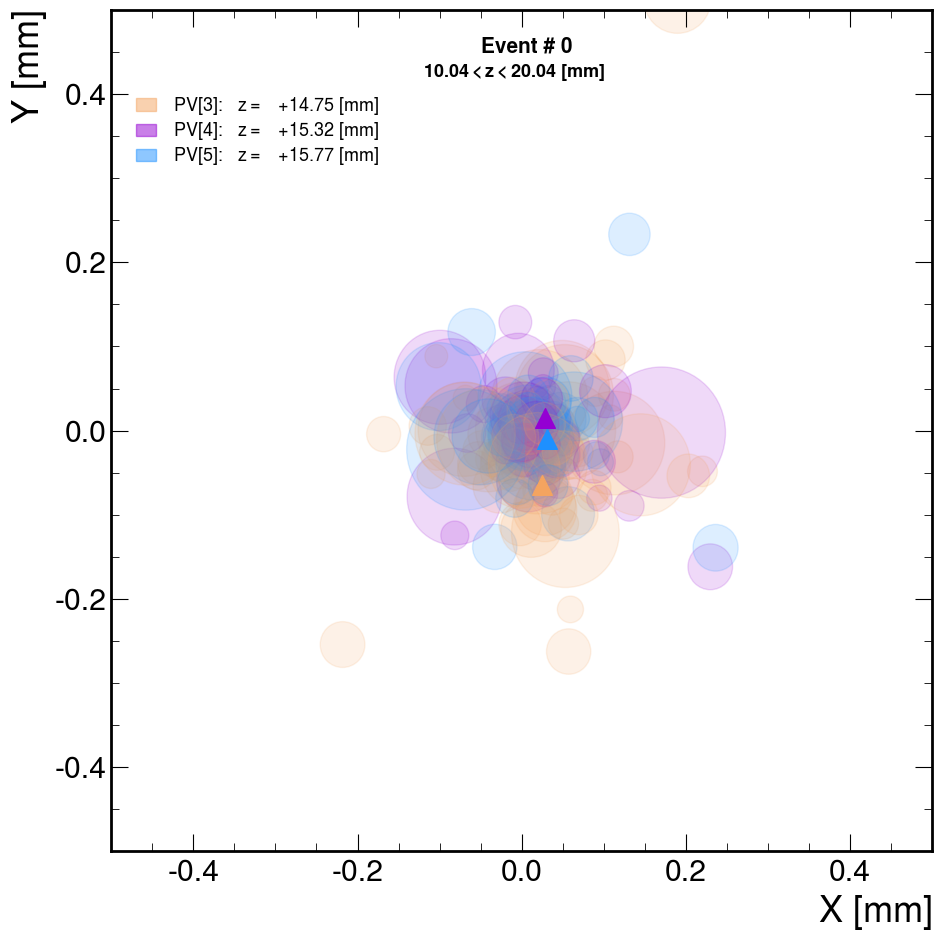

z_center= 15.036750000000001
z_center-0.05*(z_center-x_l_fram)= 14.786750000000001


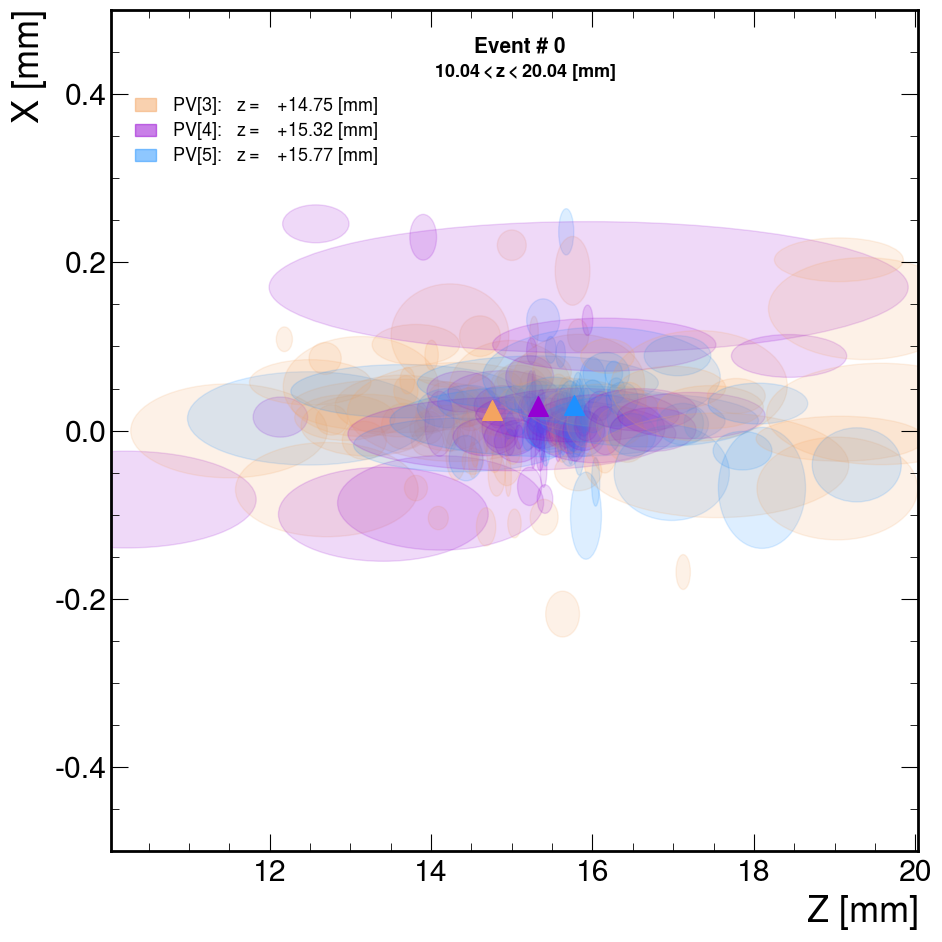

z_center= 15.036750000000001
z_center-0.05*(z_center-x_l_fram)= 14.786750000000001


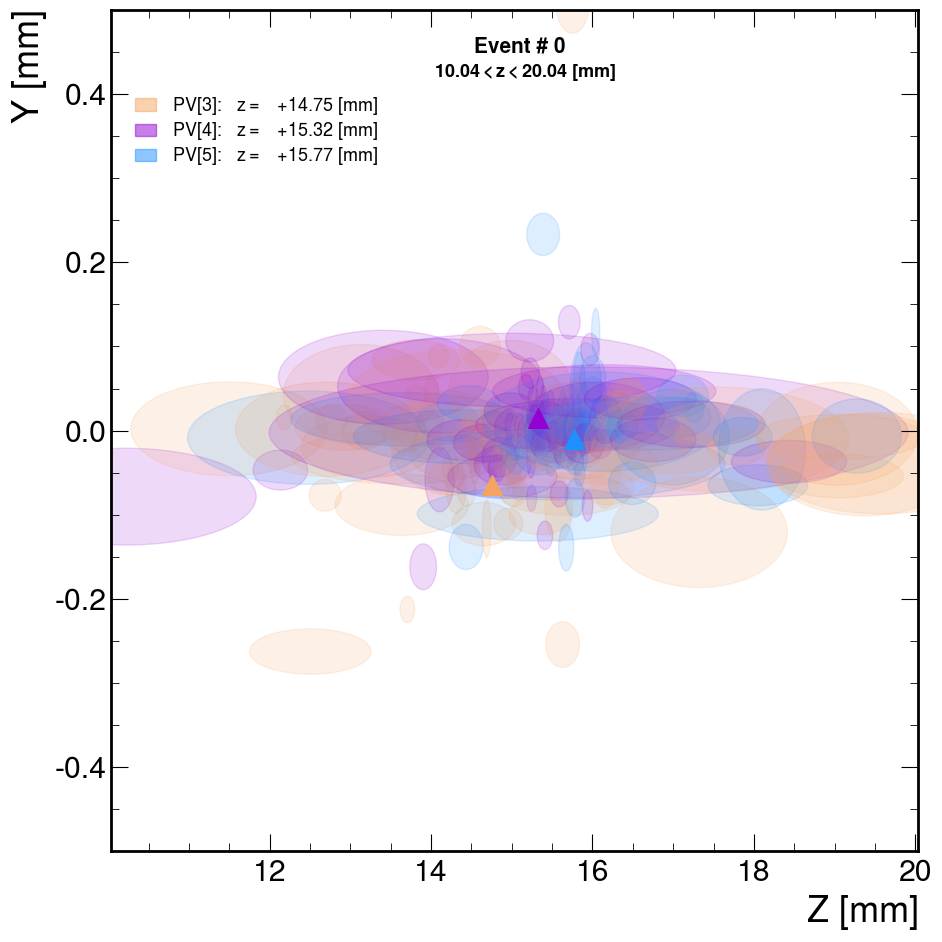

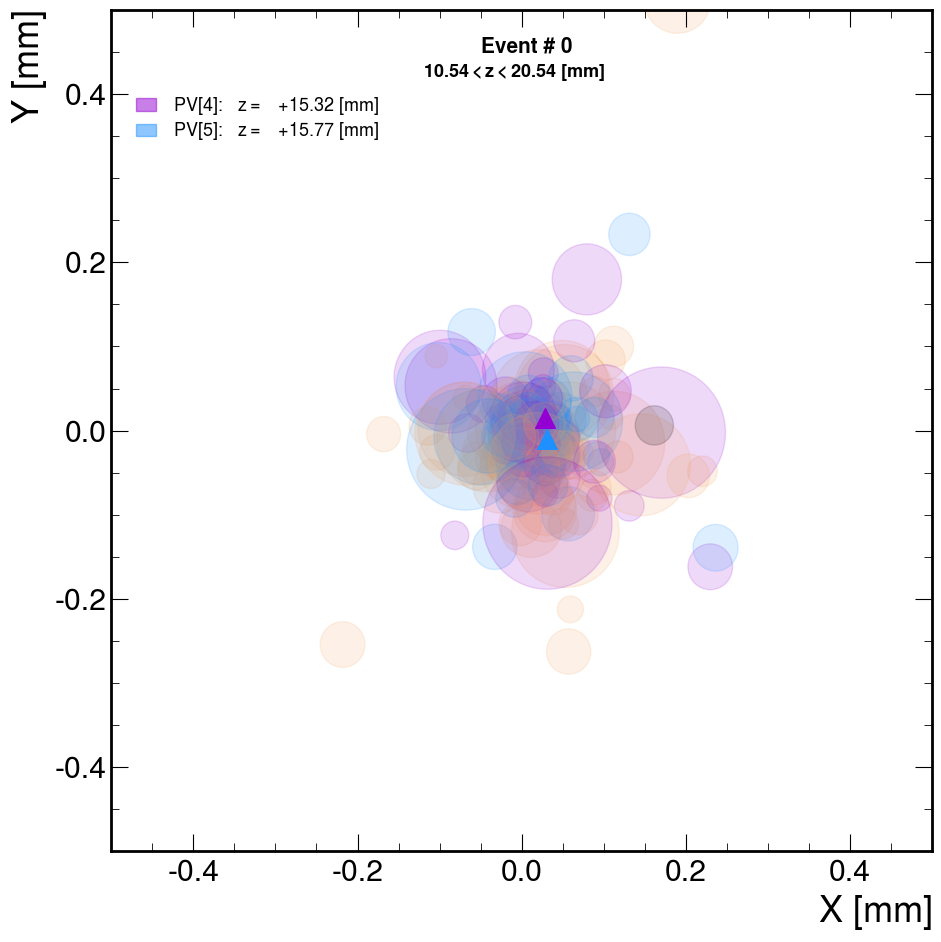

z_center= 15.54365
z_center-0.05*(z_center-x_l_fram)= 15.29365


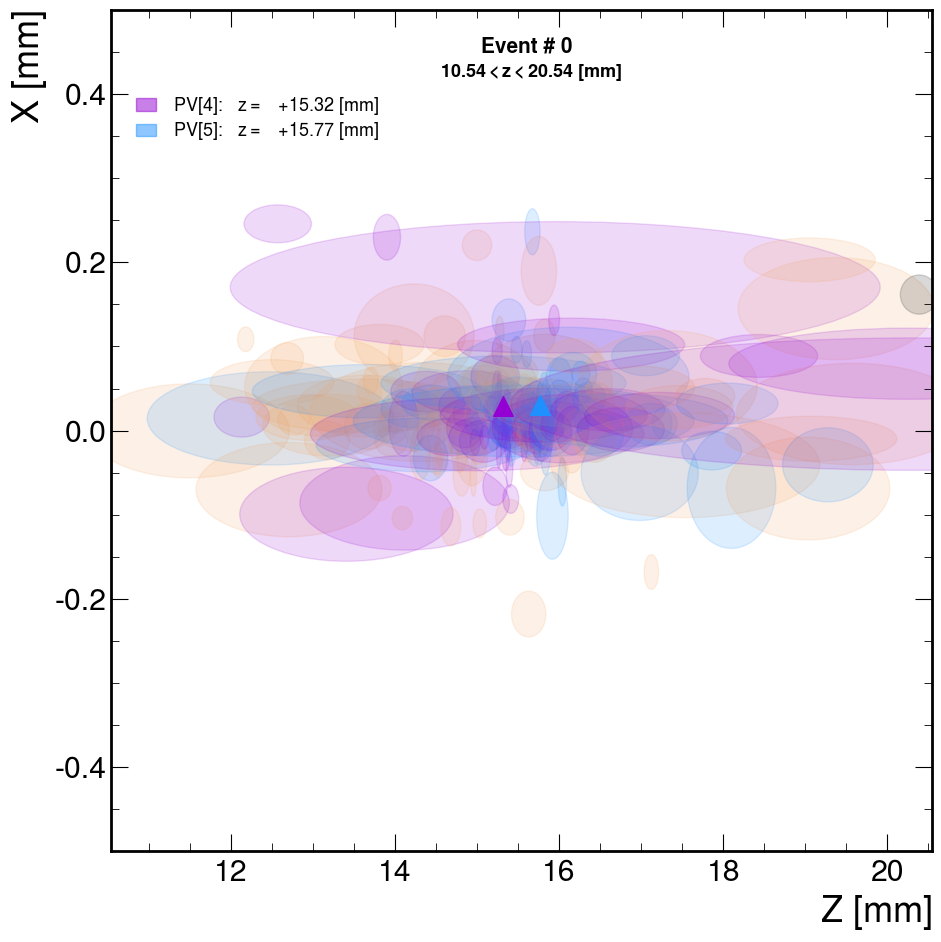

z_center= 15.54365
z_center-0.05*(z_center-x_l_fram)= 15.29365


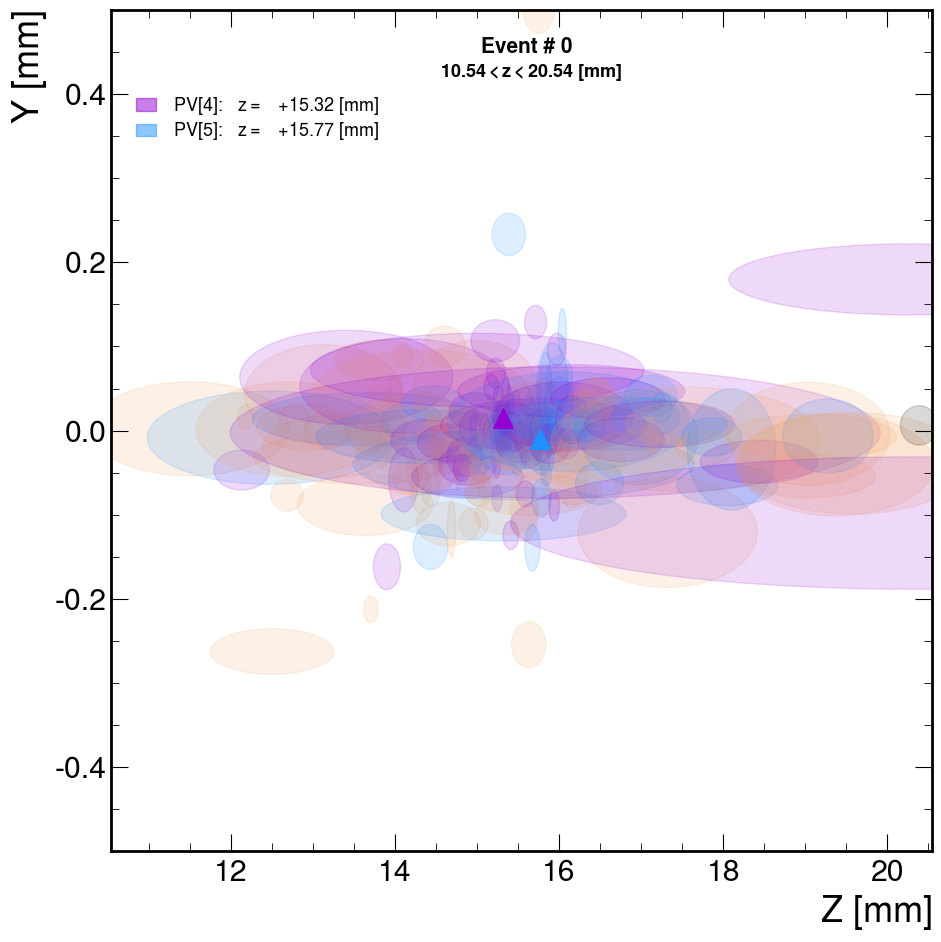

<Figure size 1000x1000 with 0 Axes>

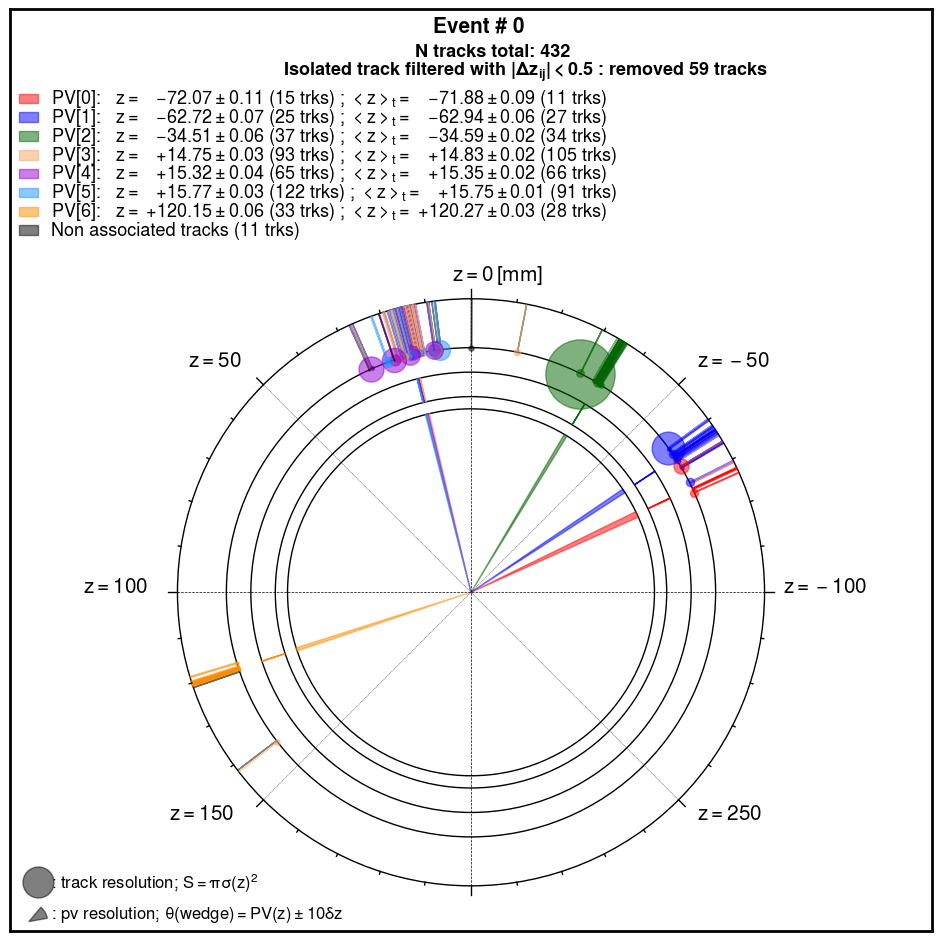

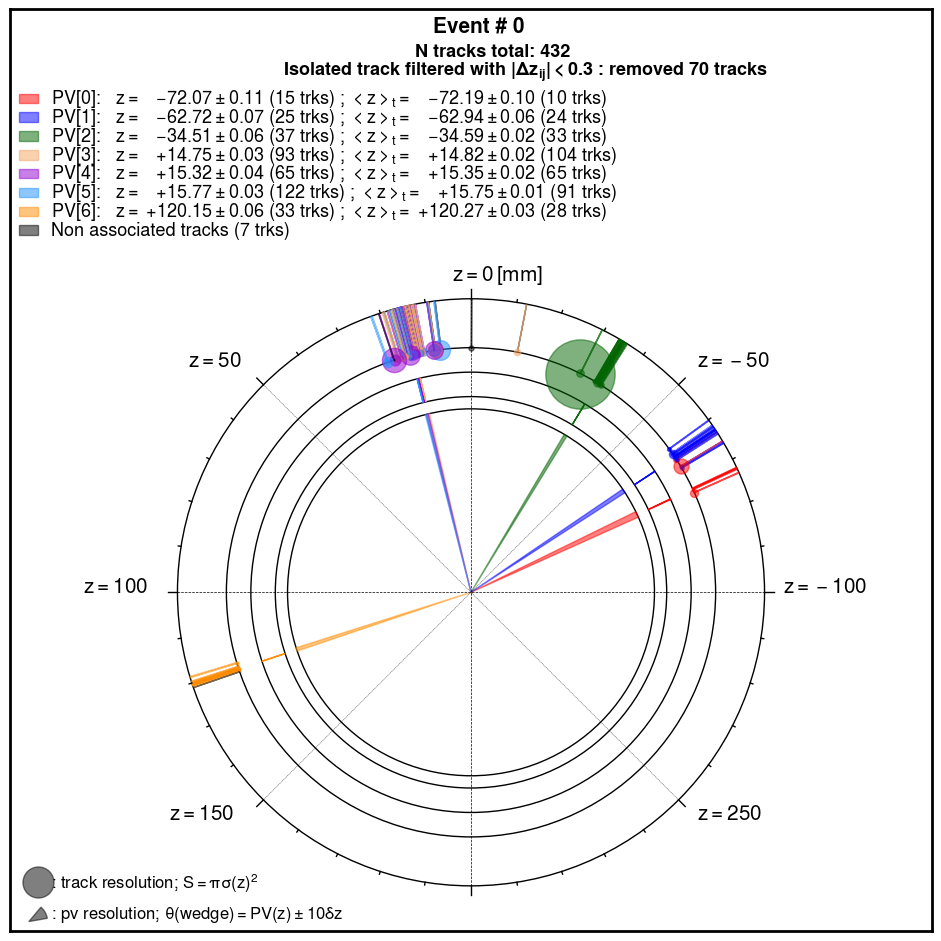

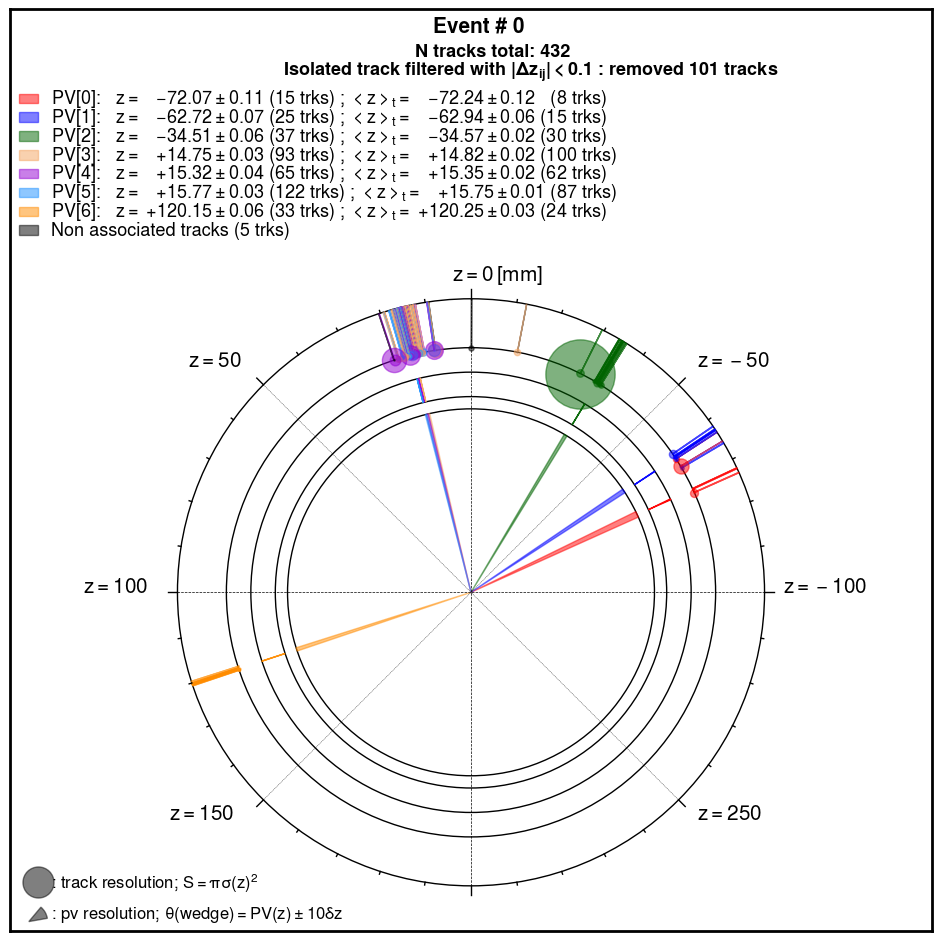

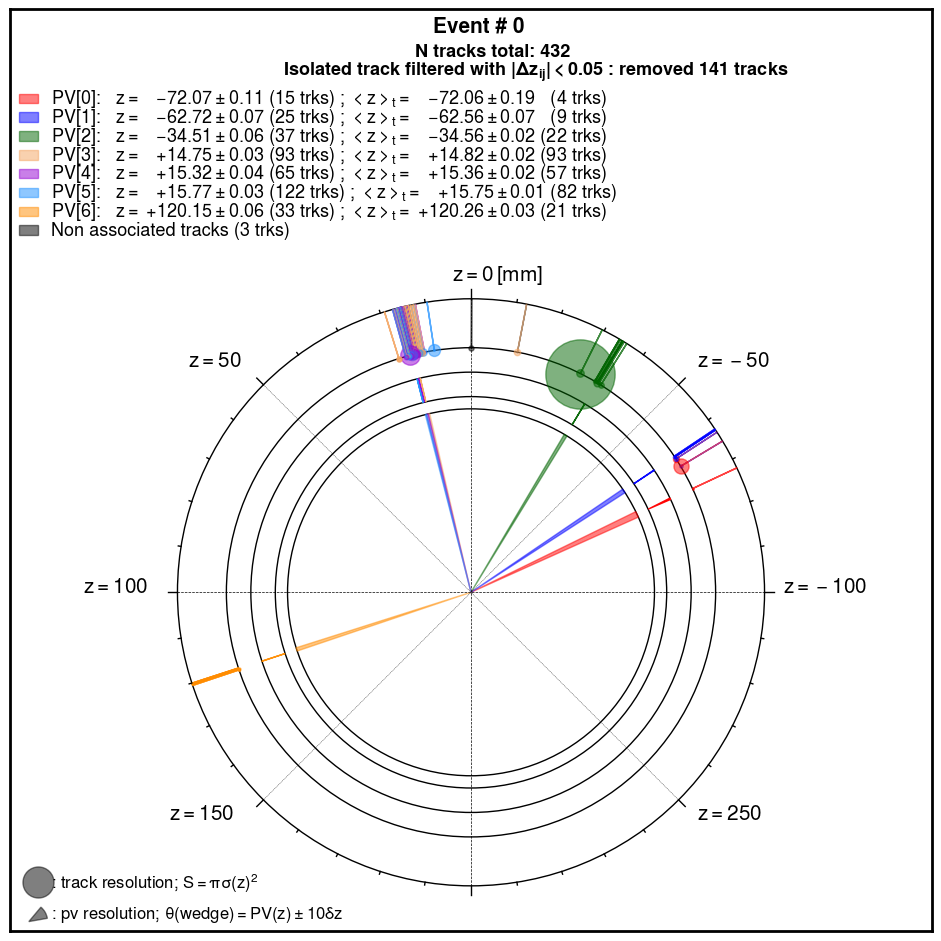

In [13]:
for iEvt in range(0,1):
    plot_tracks_polar(iEvt, 
                      pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], 
                      poca_x[iEvt], poca_sigma_x[iEvt], 
                      poca_y[iEvt], poca_sigma_y[iEvt], 
                      poca_z[iEvt], poca_sigma_z[iEvt], 
                      recon_tx[iEvt], recon_ty[iEvt], 
                      recon_pv_key[iEvt], 
                      'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', 
                      doFilt=False)
    plot_tracks_polar(iEvt, pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], poca_x[iEvt], poca_sigma_x[iEvt], poca_y[iEvt], poca_sigma_y[iEvt], poca_z[iEvt], poca_sigma_z[iEvt], recon_tx[iEvt], recon_ty[iEvt], recon_pv_key[iEvt], 'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', doFilt=True, min_d_tracks=0.5, min_d_pv=5.0)
    plot_tracks_polar(iEvt, pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], poca_x[iEvt], poca_sigma_x[iEvt], poca_y[iEvt], poca_sigma_y[iEvt], poca_z[iEvt], poca_sigma_z[iEvt], recon_tx[iEvt], recon_ty[iEvt], recon_pv_key[iEvt], 'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', doFilt=True, min_d_tracks=0.3, min_d_pv=5.0)  
    plot_tracks_polar(iEvt, pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], poca_x[iEvt], poca_sigma_x[iEvt], poca_y[iEvt], poca_sigma_y[iEvt], poca_z[iEvt], poca_sigma_z[iEvt], recon_tx[iEvt], recon_ty[iEvt], recon_pv_key[iEvt], 'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', doFilt=True, min_d_tracks=0.1, min_d_pv=5.0)    
    plot_tracks_polar(iEvt, pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], poca_x[iEvt], poca_sigma_x[iEvt], poca_y[iEvt], poca_sigma_y[iEvt], poca_z[iEvt], poca_sigma_z[iEvt], recon_tx[iEvt], recon_ty[iEvt], recon_pv_key[iEvt], 'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', doFilt=True, min_d_tracks=0.05, min_d_pv=5.0)    


In [14]:
iEvt = 50
print(pv_key[iEvt])
print(pv_z[iEvt])
print(pv_n[iEvt])
print(pv_cat[iEvt])
print(sum(pv_n[iEvt]))
print(len(poca_z[iEvt]))

[0, 1, 2, 3, 4, 5, 6]
[-48.3, -46.9, -21.3, -4.83, 18.6, 31.6, 55.9]
[9, 22, 5, 36, 47, 16, 30]
[1, 1, 1, 1, 1, 1, 1]
165
192


In [113]:
x=23.567
test = [0.0,0.25,0.5,0.75,1.0]
val=x-np.floor(x)
test[(np.abs(test - val)).argmin()]+np.floor(x)

23.5

In [15]:
for i in range(len(poca_z[iEvt])):
    if recon_pv_key[iEvt][i]>-2:
        print("track_pv_key[%i] \t = %s \t  ;  track(z)[%s] \t = %.2f +/- %.2f"%(i,int(recon_pv_key[iEvt][i]),i,poca_z[iEvt][i],poca_C[iEvt][i]))

track_pv_key[0] 	 = 6 	  ;  track(z)[0] 	 = -557.81 +/- 0.00
track_pv_key[1] 	 = -1 	  ;  track(z)[1] 	 = -353.98 +/- 0.00
track_pv_key[2] 	 = -1 	  ;  track(z)[2] 	 = -352.62 +/- 15.17
track_pv_key[3] 	 = 1 	  ;  track(z)[3] 	 = -75.90 +/- 0.02
track_pv_key[4] 	 = 1 	  ;  track(z)[4] 	 = -70.08 +/- 0.00
track_pv_key[5] 	 = -1 	  ;  track(z)[5] 	 = -66.70 +/- 2.75
track_pv_key[6] 	 = 1 	  ;  track(z)[6] 	 = -60.47 +/- 0.00
track_pv_key[7] 	 = -1 	  ;  track(z)[7] 	 = -56.66 +/- 0.64
track_pv_key[8] 	 = 1 	  ;  track(z)[8] 	 = -54.43 +/- 0.02
track_pv_key[9] 	 = -1 	  ;  track(z)[9] 	 = -51.12 +/- 51.71
track_pv_key[10] 	 = 1 	  ;  track(z)[10] 	 = -50.56 +/- 0.87
track_pv_key[11] 	 = 1 	  ;  track(z)[11] 	 = -50.21 +/- 0.19
track_pv_key[12] 	 = 1 	  ;  track(z)[12] 	 = -49.48 +/- 0.28
track_pv_key[13] 	 = 1 	  ;  track(z)[13] 	 = -49.36 +/- 0.70
track_pv_key[14] 	 = 1 	  ;  track(z)[14] 	 = -49.06 +/- 0.30
track_pv_key[15] 	 = 0 	  ;  track(z)[15] 	 = -49.01 +/- 7.42
track_pv_key[16] 	

In [16]:
iEvt=0

for i_t in range(len(poca_z[iEvt])):
    
    u1_x = minor_axis1_x[iEvt][i_t]
    u1_y = minor_axis1_y[iEvt][i_t]
    u1_z = minor_axis1_z[iEvt][i_t]
        
    u2_x = minor_axis2_x[iEvt][i_t]
    u2_y = minor_axis2_y[iEvt][i_t]
    u2_z = minor_axis2_z[iEvt][i_t]
    
    u3_x = major_axis_x[iEvt][i_t]
    u3_y = major_axis_y[iEvt][i_t]
    u3_z = major_axis_z[iEvt][i_t]
    
    u1_mag = u1_x*u1_x + u1_y*u1_y + u1_z*u1_z
    u2_mag = u2_x*u2_x + u2_y*u2_y + u2_z*u2_z
    u3_mag = u3_x*u3_x + u3_y*u3_y + u3_z*u3_z
    
    u1_x_norm = u1_x / u1_mag
    u1_y_norm = u1_y / u1_mag
    u1_z_norm = u1_z / u1_mag
    
    u2_x_norm = u2_x / u2_mag
    u2_y_norm = u2_y / u2_mag
    u2_z_norm = u2_z / u2_mag
    
    u3_x_norm = u3_x / u3_mag
    u3_y_norm = u3_y / u3_mag
    u3_z_norm = u3_z / u3_mag
    
    A = u1_x_norm*u1_x_norm + u2_x_norm*u2_x_norm + u3_x_norm*u3_x_norm
    B = u1_y_norm*u1_y_norm + u2_y_norm*u2_y_norm + u3_y_norm*u3_y_norm
    C = u1_z_norm*u1_z_norm + u2_z_norm*u2_z_norm + u3_z_norm*u3_z_norm
    print("="*100)
    #print("Track[%s]"%i_t)
    
    print("Track[%s] \t x = %.2f \t tx = %.2f  \t y = %.2f \t ty = %.2f"%(i_t,poca_x[iEvt][i_t],recon_tx[iEvt][i_t],poca_y[iEvt][i_t],recon_ty[iEvt][i_t]))
    '''
    print("")
    print("u1_x=",u1_x)
    print("u2_x=",u2_x)
    print("u3_x=",u3_x)
    print("")

    print("u1_y=",u1_y)
    print("u2_y=",u2_y)
    print("u3_y=",u3_y)
    print("")
    
    print("u1_z=",u1_z)
    print("u2_z=",u2_z)
    print("u3_z=",u3_z)
    print("")
    
    print("u1_mag=",u1_mag)
    print("u2_mag=",u2_mag)
    print("u3_mag=",u3_mag)
    print("")

    print("u1_x_norm=",u1_x_norm)
    print("u2_x_norm=",u2_x_norm)
    print("u3_x_norm=",u3_x_norm)
    print("")
    
    print("u1_y_norm=",u1_y_norm)
    print("u2_y_norm=",u2_y_norm)
    print("u3_y_norm=",u3_y_norm)
    print("")
    
    print("u1_z_norm=",u1_z_norm)
    print("u2_z_norm=",u2_z_norm)
    print("u3_z_norm=",u3_z_norm)
    print("")
    
    print("A=",A)
    print("B=",B)
    print("C=",C)
    print("")
    '''

Track[0] 	 x = 1.57 	 tx = -0.03  	 y = 18.43 	 ty = 0.00
Track[1] 	 x = 2.40 	 tx = 0.01  	 y = -3.33 	 ty = 0.01
Track[2] 	 x = 0.85 	 tx = 0.09  	 y = -0.38 	 ty = 0.21
Track[3] 	 x = 1.04 	 tx = -0.02  	 y = 1.07 	 ty = 0.02
Track[4] 	 x = -0.83 	 tx = 0.04  	 y = 2.04 	 ty = 0.01
Track[5] 	 x = -0.34 	 tx = 0.00  	 y = -0.02 	 ty = -0.01
Track[6] 	 x = -4.34 	 tx = 0.09  	 y = 15.13 	 ty = 0.03
Track[7] 	 x = -0.03 	 tx = -0.01  	 y = 0.06 	 ty = -0.01
Track[8] 	 x = -0.04 	 tx = -0.01  	 y = -0.10 	 ty = 0.00
Track[9] 	 x = 0.02 	 tx = 0.04  	 y = 0.03 	 ty = -0.02
Track[10] 	 x = -0.03 	 tx = 0.01  	 y = -0.02 	 ty = -0.01
Track[11] 	 x = -0.05 	 tx = -0.03  	 y = -0.02 	 ty = 0.09
Track[12] 	 x = -0.04 	 tx = -0.01  	 y = 0.01 	 ty = -0.04
Track[13] 	 x = -0.04 	 tx = 0.11  	 y = -0.03 	 ty = -0.19
Track[14] 	 x = 0.00 	 tx = -0.05  	 y = -0.00 	 ty = -0.04
Track[15] 	 x = -0.00 	 tx = 0.05  	 y = -0.01 	 ty = -0.02
Track[16] 	 x = 0.01 	 tx = -0.12  	 y = -0.02 	 ty = -0.06
Tr

Track[283] 	 x = 0.19 	 tx = -0.13  	 y = 0.51 	 ty = 0.05
Track[284] 	 x = 0.00 	 tx = -0.59  	 y = -0.00 	 ty = -0.13
Track[285] 	 x = 0.02 	 tx = -0.01  	 y = -0.00 	 ty = -0.45
Track[286] 	 x = 0.02 	 tx = 0.11  	 y = -0.03 	 ty = 0.07
Track[287] 	 x = -0.01 	 tx = -0.14  	 y = -0.08 	 ty = 0.01
Track[288] 	 x = -0.00 	 tx = 0.12  	 y = -0.01 	 ty = -0.09
Track[289] 	 x = -0.01 	 tx = -0.03  	 y = -0.00 	 ty = 0.04
Track[290] 	 x = 0.04 	 tx = -0.07  	 y = 0.01 	 ty = 0.19
Track[291] 	 x = 0.01 	 tx = -0.06  	 y = -0.00 	 ty = -0.13
Track[292] 	 x = -0.00 	 tx = -0.09  	 y = -0.01 	 ty = 0.01
Track[293] 	 x = 0.02 	 tx = -0.01  	 y = 0.01 	 ty = 0.02
Track[294] 	 x = 0.11 	 tx = -0.04  	 y = 0.04 	 ty = 0.10
Track[295] 	 x = 0.01 	 tx = 0.17  	 y = -0.00 	 ty = 0.30
Track[296] 	 x = 0.05 	 tx = -0.14  	 y = -0.03 	 ty = -0.20
Track[297] 	 x = -0.05 	 tx = -0.02  	 y = -0.02 	 ty = 0.05
Track[298] 	 x = 0.06 	 tx = 0.00  	 y = 0.00 	 ty = -0.05
Track[299] 	 x = 0.02 	 tx = -0.12  	 

In [6]:
d_colors = {-1:'black',
           0:'red',
           1:'blue',
           2:'darkgreen',
           3:'sandybrown',
           4:'darkviolet',
           5:'dodgerblue',
           6:'darkorange',
           7:'deeppink',
           8:'teal',
           9:'purple',
          10:'orangered',
          11:'darkblue',
          12:'crimson',
          13:'cyan',
          14:'gold',
          15:'deepskyblue',
          16:'olive',
          17:'blueviolet',
          18:'tomato',
          19:'turquoise',
         }

In [7]:
## ========================================================================================
def get_closest_round_z_val(x,template):
    val=x-np.floor(x)    
    return template[(np.abs(test - val)).argmin()]+np.floor(x)


In [8]:
## ========================================================================================
def compute_variable_range_target_hists(z_min, z_max, l_pvs_z, l_pvs_n, global_configs):
    
    template = [0.0,0.25,0.5,0.75,1.0]

    ## Get the resolutions for all vertexes
    pv_res   = get_res(l_pvs_n, global_configs)

    res_min = 0.25 ## [mm]
    ## The vertexes true resolution as a function of nTracks will be increased 
    ## if res < 150 microns such that the target peaks will get more narrow and 
    ## the areas larger as the number of tracks increases.
    pv_res_scale = np.where((res_min / pv_res) > 1, (res_min / pv_res), res_min)

    starting_z_hist = get_closest_round_z_val(z_min, template)
    ending_z_hist   = get_closest_round_z_val(z_max, template)

    z_range = ending_z_hist - starting_z_hist
    
    bin_width = 0.25 ## [mm]

    n_bins_target_hist = int(z_range / _bin_width)
    
    ## Define the z_range over n_bins_target_hist
    #zRange_over_nBins_ratio = n_bins_target_hist / z_range
    ## Bins width definition
    #bin_width = z_range/n_bins_target_hist
    half_bin_width = bin_width/2.
    
    ## Edges of the bins definition
    edges = np.array([-half_bin_width, half_bin_width])
    ## Range of z values of the target hists
    zvals_range = (z_min + half_bin_width, z_max - half_bin_width)

    ## Get the bin number corresponding to the PV position in Z: 
    pv_bin = ak.values_astype(np.floor((pv_z - zvals_range[0]) * zRange_over_nBins_ratio), "int16")

    ## This is a placeholder to hold the values of the vertexes peak structure
    ## +/- 5 bins around peak maximum seems a good compromise, as for more bins the 
    ## hist values become quickly tiny. 
    nBins_around_vtx_peak = 20    
    vtx_bins = np.arange(-nBins_around_vtx_peak, nBins_around_vtx_peak+1)
    
    ## Define the bins basis for which the normal cumulative distribution will be evaluated
    ## For each vertex, the vxt position (in z basis) will be added
    ## The output is a set of two list values corresponding to the equivalent of bins edges shifted by one bin
    vtx_z_bins_ranges = bin_width * vtx_bins[np.newaxis, :] + edges[:, np.newaxis] + zvals_range[0]

    ## Define the target histogram
    targetHists = np.zeros([n_bins_target_hist], dtype=np.float16)
    
    ## Looping over the vertexes
    for iVtx in range(len(l_pvs_z)):

        vtx_z         = l_pvs_z[iVtx]
        vtx_bin       = pv_bin[iVtx]
        vtx_res       = pv_res[iVtx]
        vtx_res_scale = pv_res_scale[iVtx]

        ## Get the bins like values of z to evaluate the normal cumulative distribution
        vtx_z_bins    = (vtx_bin / zRange_over_nBins_ratio + vtx_z_bins_ranges)

        ## Get the values of the normal cumulative ditribution for the two set of vtx_z_bins
        norm_cdf_vals = norm_cdf(vtx_z, vtx_res, vtx_z_bins)
        ## Take the difference of norm_cdf_Vals to get the normal PDF values as vtx_peak_Vals
        ## The vtx_peak_vals are further scaled based on the vtx_res_scale values defined above

        vtx_peak_vals = (norm_cdf_vals[1] - norm_cdf_vals[0])*vtx_res_scale
    
        
        targetHists[vtx_bins + vtx_bin] += vtx_peak_vals
            
    return targetHists


In [9]:
def graph_intersection(pred_graph,
                       truth_graph,
                       device,
                       using_weights=False,
                       weights_bidir=None):
    '''
    if device is None:
        device = default_device
    elif str(device) == "cuda:0":
        device = "cuda"
    '''
    
    if pred_graph.numel() > 0:
        pred_graph_max = pred_graph.max().item()
    else:
        pred_graph_max = 0

    if truth_graph.numel() > 0:
        truth_graph_max = truth_graph.max().item()
    else:
        truth_graph_max = 0

    array_size = max(pred_graph_max, truth_graph_max) + 1

    if torch.is_tensor(pred_graph):
        l1 = pred_graph.cpu().numpy()
    else:
        l1 = pred_graph
    if torch.is_tensor(truth_graph):
        l2 = truth_graph.cpu().numpy()
    else:
        l2 = truth_graph
    e_1 = scipy.sparse.coo_matrix(
        (np.ones(l1.shape[1]), l1), shape=(array_size, array_size)
    ).tocsr()
    e_2 = scipy.sparse.coo_matrix(
        (np.ones(l2.shape[1]), l2), shape=(array_size, array_size)
    ).tocsr()
    del l1

    e_intersection = e_1.multiply(e_2) - ((e_1 - e_2) > 0)
    del e_1
    del e_2

    if using_weights:
        weights_list = weights_bidir.cpu().numpy()
        weights_sparse = sp.sparse.coo_matrix(
            (weights_list, l2), shape=(array_size, array_size)
        ).tocsr()
        del weights_list
        del l2
        new_weights = weights_sparse[e_intersection.astype("bool")]
        del weights_sparse
        new_weights = torch.from_numpy(np.array(new_weights)[0])

    e_intersection = e_intersection.tocoo()
    new_pred_graph = (
        torch.from_numpy(np.vstack([e_intersection.row, e_intersection.col]))
        .long()
        .to(device)
    )
    y = torch.from_numpy(e_intersection.data > 0).to(device)
    del e_intersection

    if using_weights:
        return new_pred_graph, y, new_weights
    else:
        return new_pred_graph, y


In [10]:
def get_true_edge_indexes(recon_pv_key):
    ## Change all non associated tracks (value==-1) to it's: index*-1
    recon_pv_key[np.where(recon_pv_key <0)]= -1*np.where(recon_pv_key <0)[0]
    ## Shift of one all associated tracks (value>=0)
    recon_pv_key[np.where(recon_pv_key >=0)] = recon_pv_key[np.where(recon_pv_key >=0)]+1
    mat = np.array(recon_pv_key[:, np.newaxis]) / np.array((recon_pv_key[np.newaxis, :]))
    mat_ones = np.where(mat == 1, 1, 0)
    adj = torch.tensor(mat_ones)
    sparse  = dense_to_sparse(adj)
    coo_tensor = to_torch_coo_tensor(sparse[0])
    return sparse, adj, coo_tensor


In [11]:
def compare_adj(pred, true):
    if len(pred)==len(true):
        return torch.tensor(np.where((pred.flatten()==true.flatten())==True, 1, 0))
    else:
        print("ERROR:: predicted and true edge dense adjacency matrices with different size: %s vs %s"%(len(pred),len(true)))


In [102]:
iEvt = 0
tracks_q = 1./(poca_sigma_x*poca_sigma_y*poca_sigma_z)
print(len(tracks_q[iEvt]))
tracks_q[iEvt]

432


<Array [1.34, 10.3, 6.48e+03, ..., 11.3, 1.39e+04] type='432 * float64'>

In [103]:
m_coords    = np.column_stack((poca_x[iEvt],poca_y[iEvt],poca_z[iEvt]))
p_dist      = pdist(m_coords)
c_dist      = cdist(m_coords,m_coords)

In [104]:
len(p_dist)

93096

In [105]:
c_dist[0]

array([  0.        , 216.44053778, 355.50539991, 413.69947192,
       449.08537046, 505.49596839, 515.71010269, 522.53525825,
       525.27754454, 528.87845669, 530.35633775, 530.44343849,
       531.21127192, 531.33837928, 531.41047697, 531.49175967,
       531.51601151, 531.63176922, 532.37111597, 532.88295932,
       533.27600218, 537.55836524, 537.65075025, 537.7557282 ,
       538.15247859, 538.09599531, 538.7408518 , 539.56692639,
       539.92993077, 540.04651205, 540.35478228, 540.35904143,
       540.43100163, 540.55473735, 540.82267449, 540.9233947 ,
       540.95218011, 540.95650555, 541.06522409, 541.08428348,
       541.15989175, 541.20688302, 541.51232879, 541.69686146,
       541.85936055, 541.93559129, 542.2006185 , 542.79461837,
       543.43415697, 543.55230798, 543.86788398, 547.27409251,
       552.00210703, 559.0290002 , 559.84404782, 565.87931502,
       566.58020781, 567.84250951, 567.996446  , 568.00209404,
       568.23099685, 568.30356375, 568.40348492, 568.51

In [106]:
(432*432 - 432)/2

93096.0

In [107]:
tracks_q[iEvt]

<Array [1.34, 10.3, 6.48e+03, ..., 11.3, 1.39e+04] type='432 * float64'>

In [108]:
tracks_q_ij = np.array(tracks_q[iEvt][:, np.newaxis]) * np.array((tracks_q[iEvt][np.newaxis, :]))
tracks_q_ij

array([[1.78901117e+00, 1.37225965e+01, 8.66329531e+03, ...,
        3.46961749e+03, 1.50537946e+01, 1.85510049e+04],
       [1.37225965e+01, 1.05259071e+02, 6.64517403e+04, ...,
        2.66136743e+04, 1.15470016e+02, 1.42295341e+05],
       [8.66329531e+03, 6.64517403e+04, 4.19520498e+07, ...,
        1.68016396e+07, 7.28980740e+04, 8.98333320e+07],
       ...,
       [3.46961749e+03, 2.66136743e+04, 1.68016396e+07, ...,
        6.72899404e+06, 2.91954070e+04, 3.59779147e+07],
       [1.50537946e+01, 1.15470016e+02, 7.28980740e+04, ...,
        2.91954070e+04, 1.26671503e+02, 1.56099092e+05],
       [1.85510049e+04, 1.42295341e+05, 8.98333320e+07, ...,
        3.59779147e+07, 1.56099092e+05, 1.92363128e+08]])

In [109]:
m_dist      = cdist(m_coords, m_coords)
m_dist      = m_dist+np.eye(len(m_dist))
m_dist      = 1./m_dist
m_pot       = m_dist*tracks_q_ij

m_pot_pair = np.array([])
for i in range(len(m_pot)-1):
    m_pot_pair = np.append(m_pot_pair, [m_pot[0+i:1+i,1+i:2+i][0][0]], axis=0)
    
sum_m_pot_pair = np.sum(m_pot_pair)
m_pot_pair = m_pot_pair/sum_m_pot_pair
m_pot_pair_sort = np.sort(m_pot_pair)[::-1]
print(np.where(m_pot_pair_sort.reshape(m_pot_pair_sort.size, 1) == m_pot_pair)[1])
#print(m_pot_pair_sort)


[267 219 401 281 284 272  69 252 301 162 211  70 212 395 396 400 245 280
 407 246 266 304 291 271 172 265 394 213 285 305  77 392 228 210 186 163
 313 249 331 220 216  64 240 279 290 171 229 259 258  71 256 226 236 390
 215 278  74 295 391 227 195 257 330 303 402 399 203 209 262  68  78 314
 208 307 393 161 406 223 239 302 308 202 207 309 214 310 273 275 235 175
 182 299 300 192 204 412 139 306 255  72  40 270 294 288 247  63 194 168
  80 198 248 233 244  73 138 286 174  79 141 242 149 397 199 276  16 140
 184  15 200 173 183 243 160 193 238 154 289  32  37 234 133 237 253 185
 197 222 332 196 178 230 201 155 157  67 398  81 176  35 241 206 181 329
 156 387 221 225  36 403 322 115 268 277 150 179 333 296 409 177 264 232
 424 389 167  41 158 287 170 408 164 298 318 388 319 411 269 346 274  60
 254 410 335 418 405 145 142 334 169 344 263 218  95 224 136 165 292  59
  12 261 282 260 251 135 180  76 404 327 137 328 159 166 134 189 425 205
  82 132 336  38  13  83  66 187 312 351  22 146 23

In [111]:
m_dist      = cdist(m_coords, m_coords)
print("-"*30)
print(m_dist)
m_dist      = m_dist+np.eye(len(m_dist))
print("-"*30)
print(m_dist)
m_dist      = 1./m_dist
print("-"*30)
print(m_dist)
print("-"*30)
print(tracks_q_ij)
m_pot       = m_dist*tracks_q_ij
print("-"*30)
print(m_pot)
print(len(m_pot))


------------------------------
[[  0.         216.44053778 355.50539991 ... 933.64824234 967.63589239
  968.85164734]
 [216.44053778   0.         139.70362205 ... 718.08628952 752.12978601
  753.11571095]
 [355.50539991 139.70362205   0.         ... 578.45176306 612.45502019
  613.51455708]
 ...
 [933.64824234 718.08628952 578.45176306 ...   0.          35.37592991
   36.08622914]
 [967.63589239 752.12978601 612.45502019 ...  35.37592991   0.
   12.30524173]
 [968.85164734 753.11571095 613.51455708 ...  36.08622914  12.30524173
    0.        ]]
------------------------------
[[  1.         216.44053778 355.50539991 ... 933.64824234 967.63589239
  968.85164734]
 [216.44053778   1.         139.70362205 ... 718.08628952 752.12978601
  753.11571095]
 [355.50539991 139.70362205   1.         ... 578.45176306 612.45502019
  613.51455708]
 ...
 [933.64824234 718.08628952 578.45176306 ...   1.          35.37592991
   36.08622914]
 [967.63589239 752.12978601 612.45502019 ...  35.37592991   1.
  

In [112]:
a = np.arange(100)
a.shape = (10,10)
print(a)
np.sum(a,axis=1)

[[ 0  1  2  3  4  5  6  7  8  9]
 [10 11 12 13 14 15 16 17 18 19]
 [20 21 22 23 24 25 26 27 28 29]
 [30 31 32 33 34 35 36 37 38 39]
 [40 41 42 43 44 45 46 47 48 49]
 [50 51 52 53 54 55 56 57 58 59]
 [60 61 62 63 64 65 66 67 68 69]
 [70 71 72 73 74 75 76 77 78 79]
 [80 81 82 83 84 85 86 87 88 89]
 [90 91 92 93 94 95 96 97 98 99]]


array([ 45, 145, 245, 345, 445, 545, 645, 745, 845, 945])

In [113]:
m_pot_proj = np.sum(m_pot,axis=1)

In [114]:
m_pot_proj

array([2.78442025e+03, 3.29029035e+04, 7.31957557e+07, 2.08365550e+04,
       2.04274725e+05, 3.30860799e+04, 4.19006468e+05, 6.52020143e+05,
       4.06722783e+04, 3.14898645e+06, 2.17397016e+06, 6.80963683e+06,
       3.37385366e+07, 1.68135031e+08, 2.40516751e+07, 1.65103363e+08,
       3.41125808e+08, 2.80252733e+08, 3.83114692e+06, 1.22202894e+08,
       2.41926736e+06, 2.23387303e+06, 2.11981343e+08, 9.24312805e+06,
       3.33301425e+06, 8.43085864e+05, 1.97961137e+08, 6.35422267e+06,
       9.00948681e+06, 8.24856918e+06, 1.35163452e+06, 9.13060425e+06,
       2.24031627e+08, 3.66340452e+08, 2.02475605e+07, 4.86956762e+08,
       1.47473209e+08, 4.86396930e+08, 4.00192777e+08, 2.78193865e+07,
       3.34261616e+08, 6.67754738e+08, 9.69666914e+07, 5.77490008e+06,
       6.12956906e+06, 1.45630959e+08, 1.09346804e+06, 7.66427965e+06,
       1.00233160e+07, 3.14220123e+06, 7.62902828e+04, 3.43020828e+06,
       4.51260321e+06, 4.81101131e+07, 5.82168380e+07, 1.09474799e+07,
      

In [115]:
m_pot_proj_norm = m_pot_proj/np.sum(m_pot_proj)

In [117]:
m_pot_proj_norm = m_pot_proj_norm/np.max(m_pot_proj_norm)
print(len(m_pot_proj_norm))
m_pot_proj_norm


432


array([3.46862471e-08, 4.09880025e-07, 9.11818563e-04, 2.59566385e-07,
       2.54470337e-06, 4.12161901e-07, 5.21967253e-06, 8.12238448e-06,
       5.06665147e-07, 3.92277431e-05, 2.70817116e-05, 8.48294168e-05,
       4.20289725e-04, 2.09450180e-03, 2.99617971e-04, 2.05673553e-03,
       4.24949289e-03, 3.49118117e-03, 4.77255934e-05, 1.52231323e-03,
       3.01374426e-05, 2.78279372e-05, 2.64070671e-03, 1.15144050e-04,
       4.15202253e-05, 1.05025399e-05, 2.46605336e-03, 7.91562042e-05,
       1.12233520e-04, 1.02754571e-04, 1.68376627e-05, 1.13742312e-04,
       2.79082023e-03, 4.56359828e-03, 2.52229126e-04, 6.06614701e-03,
       1.83711212e-03, 6.05917304e-03, 4.98530550e-03, 3.46553332e-04,
       4.16398387e-03, 8.31839441e-03, 1.20793929e-03, 7.19394320e-05,
       7.63576358e-05, 1.81416273e-03, 1.36216157e-05, 9.54759247e-05,
       1.24863054e-04, 3.91432178e-05, 9.50367891e-07, 4.27309966e-05,
       5.62146717e-05, 5.99320190e-04, 7.25222290e-04, 1.36375604e-04,
      

In [27]:
for i in range(len(m_pot)-1):
    if m_pot_pair[i]>0.000005:
        print("Potential between tracks %s (z=%.1f) and %s (z=%.1f) ==> %.3f [true PV key: %s]"%(0+i, poca_z[iEvt][0+i], 1+i, poca_z[iEvt][1+i], m_pot_pair[i], (True if recon_pv_key[iEvt][0+i] == recon_pv_key[iEvt][1+i] else False)))


Potential between tracks 12 (z=-72.4) and 13 (z=-72.3) ==> 0.000 [true PV key: True]
Potential between tracks 13 (z=-72.3) and 14 (z=-72.2) ==> 0.000 [true PV key: True]
Potential between tracks 14 (z=-72.2) and 15 (z=-72.1) ==> 0.000 [true PV key: True]
Potential between tracks 15 (z=-72.1) and 16 (z=-72.1) ==> 0.001 [true PV key: True]
Potential between tracks 16 (z=-72.1) and 17 (z=-72.0) ==> 0.001 [true PV key: True]
Potential between tracks 18 (z=-71.3) and 19 (z=-70.8) ==> 0.000 [true PV key: True]
Potential between tracks 21 (z=-66.1) and 22 (z=-66.0) ==> 0.000 [true PV key: True]
Potential between tracks 22 (z=-66.0) and 23 (z=-65.9) ==> 0.000 [true PV key: True]
Potential between tracks 26 (z=-64.9) and 27 (z=-64.1) ==> 0.000 [true PV key: True]
Potential between tracks 31 (z=-63.3) and 32 (z=-63.2) ==> 0.000 [true PV key: True]
Potential between tracks 32 (z=-63.2) and 33 (z=-63.1) ==> 0.001 [true PV key: True]
Potential between tracks 33 (z=-63.1) and 34 (z=-62.8) ==> 0.000 

In [28]:
edg_indexes_true, adj_true, coo_tensor = get_true_edge_indexes(ak.to_numpy(recon_pv_key[0]))
edg_indexes_true[0]

tensor([[  0,   0,   0,  ..., 430, 430, 431],
        [  0,   7,  10,  ..., 426, 430, 431]])

In [29]:
adj_true

tensor([[1, 0, 0,  ..., 0, 0, 0],
        [0, 1, 0,  ..., 0, 0, 0],
        [0, 0, 1,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 1, 0, 0],
        [0, 0, 0,  ..., 0, 1, 0],
        [0, 0, 0,  ..., 0, 0, 1]])

In [30]:
s = slice(0,10)
a = np.arange(0, 20, 1)
a[s]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [31]:
coo_tensor.values()

tensor([1., 1., 1.,  ..., 1., 1., 1.])

In [32]:
one = np.array([ 1,3,1,1 ])
two = np.array([ 1,3,1,1 ])
mat = (recon_pv_key[iEvt][:, np.newaxis]) / (recon_pv_key[iEvt][np.newaxis, :])
print(np.array(recon_pv_key[iEvt]))
mat = (recon_pv_key[iEvt][:, np.newaxis]+0.01) / (recon_pv_key[iEvt][np.newaxis, :]+0.01)
mat_neg = (recon_pv_key[iEvt][:, np.newaxis]+0.01) / (recon_pv_key[iEvt][np.newaxis, :]+0.01)*-1
mat_filt_ones = np.where(mat == 1, 1, 0)
mat_filt_ones = np.where(mat == 1, 1, 0)
mat_filt_ones = np.array(mat_filt_ones)
print(mat_filt_ones[0])
print(np.array(mat_neg)[0])
mat_filt_ones_filt_non_ass = np.where(mat_neg < 0, 0, mat_filt_ones)
print(mat_filt_ones_filt_non_ass[0])

[   1.    6.   -2.    6.    4.    2.   -6.    1.    2.    2.    1.    1.
    1.    1.    1.    1.    1.    1.    1.    1.    2.    2.    2.    2.
    2.    1.    2.    2.    2.    2.    1.    2.    2.    2.    2.    2.
    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.
    2.    2.    2.  -51.  -52.  -53.  -54.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.  -91.  -92.    3.    4.  -95.
  -96.    4.    6.  -99. -100.    6. -102. -103.    6.    6. -106. -107.
    4.    4.    6.    6.    5.    5.    4.    5.    4.    6.    4.    5.
    4.    4.    4.    4.    6.    4.    4.    4.    5.    4.    4.    4.
    6.    4.    4.    4.    4.    5.    4.    4.    4.    4.    4.    5.
    5.    4.    6.    4.    4.    4.    4.    4.    4.    6.    5.    4.
    6.    4.    4.    6.    4.    4.    4.    4.   

In [33]:
row = 1
mat_filt_neg = (recon_pv_key[iEvt][:, np.newaxis]) * (recon_pv_key[iEvt][np.newaxis, :])*-1
mat_filt_neg = np.where(mat_filt_neg == -1, -1, 0)
mat = (recon_pv_key[iEvt][:, np.newaxis]+0.01) / (recon_pv_key[iEvt][np.newaxis, :]+0.01)
print(np.array(recon_pv_key[iEvt]))
#print(np.array(mat[row]))
mat_ones = np.where(mat == 1, 1, 0)
mat_ones = np.array(mat_ones)
print(np.array(mat_ones[row]))
mat_ones = mat_ones + mat_filt_neg
print(np.array(mat_ones[row]))

[   1.    6.   -2.    6.    4.    2.   -6.    1.    2.    2.    1.    1.
    1.    1.    1.    1.    1.    1.    1.    1.    2.    2.    2.    2.
    2.    1.    2.    2.    2.    2.    1.    2.    2.    2.    2.    2.
    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.    2.
    2.    2.    2.  -51.  -52.  -53.  -54.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.    3.
    3.    3.    3.    3.    3.    3.    3.  -91.  -92.    3.    4.  -95.
  -96.    4.    6.  -99. -100.    6. -102. -103.    6.    6. -106. -107.
    4.    4.    6.    6.    5.    5.    4.    5.    4.    6.    4.    5.
    4.    4.    4.    4.    6.    4.    4.    4.    5.    4.    4.    4.
    6.    4.    4.    4.    4.    5.    4.    4.    4.    4.    4.    5.
    5.    4.    6.    4.    4.    4.    4.    4.    4.    6.    5.    4.
    6.    4.    4.    6.    4.    4.    4.    4.   

In [13]:
def get_sp_adj(x,y,z,max_d):
    m_coords    = np.column_stack((x,y,z))
    m_dist      = cdist(m_coords, m_coords)
    m_dist_filt = np.where(m_dist < max_d, 1, 0)
    m_adj       = torch.tensor(m_dist_filt)
    m_sp_adj    = dense_to_sparse(m_adj)
    return m_sp_adj, m_adj, m_dist

In [14]:
def _connected_components_cpu_np(edge_index, max_node_idx: int):
    """Apply the connected components algorithm on CPU."""
    if edge_index.shape[0]:
        import scipy.sparse as sps

        sparse_edges = sps.coo_matrix((np.ones(edge_index[0].shape),(edge_index[0], edge_index[1]),),(max_node_idx + 1, max_node_idx + 1),)

        _, candidate_labels = sps.csgraph.connected_components(sparse_edges, directed=False, return_labels=True)

        return pd.DataFrame({"track_idx": np.arange(max_node_idx + 1),
                             "group_id": candidate_labels,
                            })
    else:
        return pd.DataFrame({"track_idx": [],
                             "group_id": [],
                            })

In [15]:
def tracks_isolation(tracks_z, tracks_sz, min_dz=0.5, max_sz=5):
    tracks_iso = np.ones(ak.to_numpy(tracks_z).shape)
        
    for iTrack in range(0,len(tracks_z)-1):
        dz = tracks_z[iTrack+1]-tracks_z[iTrack]
        if dz<min_dz:
            tracks_iso[iTrack+1] = 0
            tracks_iso[iTrack]   = 0
            
    for iTrack in range(0,len(tracks_z)):
        if tracks_sz[iTrack]>max_sz:
            tracks_iso[iTrack]   = 1
        
    return tracks_iso



In [16]:
def tracks_isolation_bis(tracks_z, tracks_sz, min_dz=0.5, max_sz=5):
    tracks_iso = np.ones(ak.to_numpy(tracks_z).shape)
    
    
    for iTrack in range(0,len(tracks_z)):
        if tracks_sz[iTrack]>max_sz:
            tracks_iso[iTrack]   = 1

    for iTrack in range(0,len(tracks_z)-1):
        dz = tracks_z[iTrack+1]-tracks_z[iTrack]
        if dz<min_dz:
            tracks_iso[iTrack+1] = 0
            tracks_iso[iTrack]   = 0
            
        
    return tracks_iso


In [17]:
iEvt=5

In [18]:
t_z = ak.to_numpy(poca_z[iEvt])
t_sz = ak.to_numpy(poca_sigma_z[iEvt])
for iTrack in range(len(t_z)):
    print("Track [%s]: z = %.2f +/- %.2f"%(iTrack,t_z[iTrack],t_sz[iTrack]))


Track [0]: z = -252.92 +/- 1.64
Track [1]: z = -241.66 +/- 0.05
Track [2]: z = -193.72 +/- 0.28
Track [3]: z = -154.01 +/- 4.47
Track [4]: z = -94.88 +/- 1.36
Track [5]: z = -87.35 +/- 1.02
Track [6]: z = -85.50 +/- 3.79
Track [7]: z = -85.30 +/- 3.81
Track [8]: z = -81.22 +/- 0.61
Track [9]: z = -80.52 +/- 0.29
Track [10]: z = -80.29 +/- 0.10
Track [11]: z = -80.16 +/- 0.10
Track [12]: z = -80.11 +/- 0.10
Track [13]: z = -80.06 +/- 0.13
Track [14]: z = -79.71 +/- 0.13
Track [15]: z = -79.36 +/- 11.00
Track [16]: z = -79.28 +/- 0.33
Track [17]: z = -69.08 +/- 2.58
Track [18]: z = -58.84 +/- 2.10
Track [19]: z = -47.71 +/- 3.23
Track [20]: z = -44.68 +/- 1.29
Track [21]: z = -40.60 +/- 0.13
Track [22]: z = -40.02 +/- 0.35
Track [23]: z = -39.98 +/- 0.30
Track [24]: z = -39.76 +/- 0.13
Track [25]: z = -39.64 +/- 0.09
Track [26]: z = -39.58 +/- 0.09
Track [27]: z = -39.43 +/- 1.09
Track [28]: z = -38.94 +/- 0.26
Track [29]: z = -38.54 +/- 4.09
Track [30]: z = -37.98 +/- 0.23
Track [31]: z

In [19]:
def get_weighted_variance(tracks_z,tracks_z_sigma):
    
    w_z     = np.power(tracks_z_sigma,-2)
    sum_w_z = np.sum(w_z)
    mu_w_z  = np.sum(w_z * tracks_z)/sum_w_z
    var_w_z = np.sum(w_z * np.power(tracks_z-mu_z,2))/sum_w_z
    
    return var_z

In [20]:
def get_group_tracks_loc(tracks_x, tracks_y, tracks_z, 
                         tracks_x_sigma, tracks_y_sigma, tracks_z_sigma):

    w_x = np.power(tracks_x_sigma,-2)
    w_y = np.power(tracks_y_sigma,-2)
    w_z = np.power(tracks_z_sigma,-2)
    
    sum_w_x = np.sum(w_x)
    sum_w_y = np.sum(w_y)
    sum_w_z = np.sum(w_z)

    sum_w_x_sq = np.power(sum_w_x,2)
    sum_w_y_sq = np.power(sum_w_y,2)
    sum_w_z_sq = np.power(sum_w_z,2)

    mu_x = np.sum(w_x * tracks_x)/sum_w_x
    mu_y = np.sum(w_y * tracks_y)/sum_w_y
    mu_z = np.sum(w_z * tracks_z)/sum_w_z

    var_x = np.sum(w_x * np.power(tracks_x-mu_x,2))/sum_w_x
    var_y = np.sum(w_y * np.power(tracks_y-mu_y,2))/sum_w_y
    var_z = np.sum(w_z * np.power(tracks_z-mu_z,2))/sum_w_z
    
    s_x = 1./np.sqrt(sum_w_x)
    s_y = 1./np.sqrt(sum_w_y)
    s_z = 1./np.sqrt(sum_w_z)
        
    return mu_x, mu_y, mu_z, s_x, s_y, s_z, var_x, var_y, var_z


In [21]:
def compare_group_to_PV(group_z, group_sz, group_vz, group_dz, l_true_z):
    matched = False
    matchedPV = 0
    for true_z in l_true_z:
        #if abs(group_z-true_z)<min(5*max(group_sz,np.sqrt(group_vz)),2.0):
        if abs(group_z-true_z)<max(group_sz, group_vz, group_dz):
            matched = True
            matchedPV+=1
    return matched, matchedPV


In [22]:
def get_grouped_tracks_info(min_d,
                            iso_d,
                            max_sz,
                            min_tracks_group,
                            tracks_x, tracks_y, tracks_z, 
                            tracks_x_sigma, tracks_y_sigma, tracks_z_sigma, verbose=False):

    ## Filter isolated tracks and tracks with large Z uncertainty 
    filt = tracks_isolation(tracks_z,tracks_z_sigma,iso_d,max_sz)
    tracks_x = tracks_x[filt==False]
    tracks_y = tracks_y[filt==False]
    tracks_z = tracks_z[filt==False]
    tracks_x_sigma = tracks_x_sigma[filt==False]
    tracks_y_sigma = tracks_y_sigma[filt==False]
    tracks_z_sigma = tracks_z_sigma[filt==False]
    
    ## Get the sparse adjacency matrix
    m_sp_adj, _, _ = get_sp_adj(tracks_x, tracks_y, tracks_z, min_d)
    ## Get the linked tracks using the connected_components
    #tracks_pvs_link = _connected_components_cpu_np(m_sp_adj[0],len(tracks_x)-1)
    tracks_links = _connected_components_cpu_np(m_sp_adj[0],len(tracks_x)-1)
    
    ## Get the indices of the tracks forming groups of more than two tracks
    #grouped_tracks_idx = tracks_links.sort_index().groupby('group_id').filter(lambda group: len(group) > 2)["track_idx"].tolist()
    grouped_tracks_idx = tracks_links.sort_index().groupby('group_id').filter(lambda group: len(group) >= min_tracks_group)["track_idx"].tolist()

    ## Get the predicted pvs identifier (group of more than one track)
    #list_mult_tracks_pvs_id = tracks_links["group_id"][grouped_tracks_idx].unique()
    groups_id = tracks_links["group_id"][grouped_tracks_idx].unique()

    grouped_tracks_info = {}
    for i in range(len(groups_id)):
        tracks_idx = tracks_links["track_idx"][tracks_links["group_id"]==groups_id[i]].tolist()
        n_tracks_group = len(tracks_idx)
        if n_tracks_group>6:
            mu_x, mu_y, mu_z, s_x, s_y, s_z, var_x, var_y, var_z = get_group_tracks_loc(tracks_x[tracks_idx[2:-2]],
                                                                                        tracks_y[tracks_idx[2:-2]],
                                                                                        tracks_z[tracks_idx[2:-2]],
                                                                                        tracks_x_sigma[tracks_idx[2:-2]],
                                                                                        tracks_y_sigma[tracks_idx[2:-2]],
                                                                                        tracks_z_sigma[tracks_idx[2:-2]])
        elif n_tracks_group<=6 and n_tracks_group>3:
            mu_x, mu_y, mu_z, s_x, s_y, s_z, var_x, var_y, var_z = get_group_tracks_loc(tracks_x[tracks_idx[1:-1]],
                                                                                        tracks_y[tracks_idx[1:-1]],
                                                                                        tracks_z[tracks_idx[1:-1]],
                                                                                        tracks_x_sigma[tracks_idx[1:-1]],
                                                                                        tracks_y_sigma[tracks_idx[1:-1]],
                                                                                        tracks_z_sigma[tracks_idx[1:-1]])
        else:
            mu_x, mu_y, mu_z, s_x, s_y, s_z, var_x, var_y, var_z = get_group_tracks_loc(tracks_x[tracks_idx],
                                                                                        tracks_y[tracks_idx],
                                                                                        tracks_z[tracks_idx],
                                                                                        tracks_x_sigma[tracks_idx],
                                                                                        tracks_y_sigma[tracks_idx],
                                                                                        tracks_z_sigma[tracks_idx])
                    
        grouped_tracks_info[i] = {"x":mu_x,"y":mu_y,"z":mu_z,
                                  "sx":s_x,"sy":s_y,"sz":s_z,
                                  "vx":var_x,"vy":var_y,"vz":var_z,
                                  "n":n_tracks_group,
                                  "zmin":tracks_z[tracks_idx[0]],"zmax":tracks_z[tracks_idx[-1]]
                                 }
        if verbose:
            print("Group  [%s]"%i)
            print("z :",tracks_z[tracks_idx])
            print("sz:",tracks_z_sigma[tracks_idx])
            print("vz=",var_z)
    return grouped_tracks_info

In [23]:
def get_GNN_data(iEvt,
                 group_idx,
                 min_d,
                 iso_d,
                 max_sz,
                 min_tracks_group,
                 tracks_x, tracks_y, tracks_z, 
                 tracks_sx, tracks_sy, tracks_sz, 
                 tracks_D, tracks_E, tracks_F,
                 true_links,
                 verbose,
                 edge_construction
                ):
    
    original_idx = np.arange(0, len(tracks_x), 1)
    
    print("Initial original_idx",original_idx)
    print("Initial number of tracks",len(tracks_x))
    
    ## Filter isolated tracks and tracks with large Z uncertainty 
    filt = tracks_isolation(tracks_z, tracks_sz, iso_d, max_sz)        
    
    tracks_x_acc  = tracks_x[filt==False]
    tracks_y_acc  = tracks_y[filt==False]
    tracks_z_acc  = tracks_z[filt==False]
    tracks_sx_acc = tracks_sx[filt==False]
    tracks_sy_acc = tracks_sy[filt==False]
    tracks_sz_acc = tracks_sz[filt==False]
    tracks_D_acc  = tracks_D[filt==False]
    tracks_E_acc  = tracks_E[filt==False]
    tracks_F_acc  = tracks_F[filt==False]

    tracks_x_rej  = tracks_x[filt==True]
    tracks_y_rej  = tracks_y[filt==True]
    tracks_z_rej  = tracks_z[filt==True]
    tracks_sx_rej = tracks_sx[filt==True]
    tracks_sy_rej = tracks_sy[filt==True]
    tracks_sz_rej = tracks_sz[filt==True]
    tracks_D_rej  = tracks_D[filt==True]
    tracks_E_rej  = tracks_E[filt==True]
    tracks_F_rej  = tracks_F[filt==True]
        
    original_idx_acc = original_idx[filt==False]
    original_idx_rej = original_idx[filt==True]
    
    print("N accepted tracks =",len(tracks_x_acc))
    
    print("Accepted tracks indices\n",original_idx_acc)
    print("Rejected tracks indices\n",original_idx_rej)
    #print("with z values\n",tracks_z[original_idx_rej])
    #print("with z values\n",tracks_z_rej)
    
    print("")
    print("")
    print("")
    print("")
    ## Get the sparse adjacency matrix
    m_sp_adj, m_adj, m_dist = get_sp_adj(tracks_x_acc, tracks_y_acc, tracks_z_acc, min_d)
    
    #print("m_sp_adj[0]",m_sp_adj[0])
    #print("m_adj[0]",m_adj[0])
    #print("m_dist[0]",m_dist[0])
    
    
    ## Get the linked tracks using the connected_components
    tracks_links = _connected_components_cpu_np(m_sp_adj[0],len(tracks_x_acc)-1)
    '''
    print(tracks_links[-2:])
    '''
    #print("tracks_links[group_id]",tracks_links["group_id"].tolist())
    
    ## Get the indices of the tracks forming groups of more than "N=min_tracks_group" tracks
    grouped_tracks_idx = tracks_links.sort_index().groupby('group_id').filter(lambda group: len(group) >= min_tracks_group)["track_idx"].tolist()
    grouped_tracks_idx_rejected = tracks_links.sort_index().groupby('group_id').filter(lambda group: len(group) < min_tracks_group)["track_idx"].tolist()
    print("grouped_tracks_idx",grouped_tracks_idx)
    print("grouped_tracks_idx_rejected",grouped_tracks_idx_rejected)
    print("original_idx_acc[grouped_tracks_idx_rejected]",original_idx_acc[grouped_tracks_idx_rejected])
    ## Get the predicted pvs identifier (group of more than min_tracks_group tracks)
    groups_id = tracks_links["group_id"][grouped_tracks_idx].unique()
    
    print("groups_id",groups_id)
    
    l_data = []
    for iGroup in range(len(groups_id)):
        print("")
        print("*"*50)
        print("*"*50)
        
        ## Get the tracks index corresponding to the considered group of tracks
        tracks_idx = tracks_links["track_idx"][tracks_links["group_id"]==groups_id[iGroup]].tolist()
        
        #print("tracks_idx",tracks_idx)
        #print("len(tracks_idx)",len(tracks_idx))
        
        start = tracks_idx[0]
        end   = tracks_idx[-1]+1
        
        print("Group %s: start = %s,  end = %s"%(iGroup,start,end-1))
        #print("original_idx_acc[start:end]\n",original_idx_acc[start:end])
        print("original_idx_acc[tracks_idx]\n",original_idx_acc[tracks_idx])
        print("          z[%s,%s] = [%.2f,%.2f]"%(start,end,tracks_z[start],tracks_z[end-1]))
        
        #print("tracks_z_acc[start:end]\n",tracks_z_acc[start:end])
        #print("tracks_z_acc[tracks_idx]\n",tracks_z_acc[tracks_idx])
        
        ## Get the edge indices
        if edge_construction==0:
            m_adj_group = np.ones(len(tracks_idx)*len(tracks_idx))
            m_adj_group.shape = (len(tracks_idx),len(tracks_idx))
            m_adj_group = torch.tensor(m_adj_group)
        else :
            m_adj_group = m_adj[start:end,start:end]
            #m_adj_group = m_adj[tracks_idx,tracks_idx]
            
        ## Remove self-loop edges:
        m_adj_group = m_adj_group - np.eye(len(m_adj_group))

        ## Remove bidir edges:
        #m_adj_group = np.triu(m_adj_group, k=1)
        
        print("len(m_adj_group)",len(m_adj_group))
        print("m_adj_group",m_adj_group)
        edge_index_group = dense_to_sparse(m_adj_group)
        
        ## Get the input features
        tracksData_group = np.stack((tracks_x_acc[tracks_idx],
                                     tracks_y_acc[tracks_idx],
                                     tracks_z_acc[tracks_idx],
                                     tracks_sx_acc[tracks_idx],
                                     tracks_sy_acc[tracks_idx],
                                     tracks_sz_acc[tracks_idx],
                                     tracks_D_acc[tracks_idx],
                                     tracks_E_acc[tracks_idx],
                                     tracks_F_acc[tracks_idx]),axis=1)
    
        x_group = torch.tensor(tracksData_group)
        
        ## Get the true edge indices for the tracks in the group:        
        #print("true_links[original_idx_acc[start:end]]\n",true_links[original_idx_acc[start:end]])
        #print(" of length =",len(true_links[original_idx_acc[start:end]]))
        print("true_links[original_idx_acc[tracks_idx]]\n",true_links[original_idx_acc[tracks_idx]])
        print(" of length =",len(true_links[original_idx_acc[tracks_idx]]))
        
        y_group, m_adj_true, _ = get_true_edge_indexes(true_links[original_idx_acc[tracks_idx]])

        
        print("len(m_adj_true)",len(m_adj_true))
        
        if edge_construction==0 or edge_construction==1:
            matching_tensor = compare_adj(m_adj_group,m_adj_true)
            l_data.append(Data(x=x_group, edge_index=edge_index_group[0], y=matching_tensor, evt=iEvt, evt_group_idx=iGroup, global_group_idx=group_idx))
        else: 
            edge_index_group, matching_tensor = graph_intersection(edge_index_group[0],y_group[0],device=None)
            l_data.append(Data(x=x_group, edge_index=edge_index_group, y=matching_tensor, evt=iEvt, evt_group_idx=iGroup, global_group_idx=group_idx))
            
        if matching_tensor == None:
            print("iEvt",iEvt)
            print("iGroup",iGroup)
        else:
            print("len(matching_tensor)",len(matching_tensor))
        
        
        group_idx+=1
    return l_data, group_idx

In [25]:
min_d  = 10
iso_d  = 0.5
max_sz = 10000
min_tracks_group = 4
nEvts=100

In [90]:
group_idx=0
l_data_fully = []
for iEvt in range(0,2):
    data, group_idx = get_GNN_data(iEvt,
                        group_idx,
                        min_d,
                        iso_d,
                        max_sz,
                        min_tracks_group,
                        ak.to_numpy(poca_x[iEvt]),
                        ak.to_numpy(poca_y[iEvt]),
                        ak.to_numpy(poca_z[iEvt]),
                        ak.to_numpy(poca_sigma_x[iEvt]),
                        ak.to_numpy(poca_sigma_y[iEvt]),
                        ak.to_numpy(poca_sigma_z[iEvt]),
                        ak.to_numpy(poca_D[iEvt]),
                        ak.to_numpy(poca_E[iEvt]),
                        ak.to_numpy(poca_F[iEvt]),
                        ak.to_numpy(recon_pv_key[iEvt]),
                        verbose=False,
                        edge_construction=2
                       )
    for idata in data:
        l_data_fully.append(idata)
len(l_data_fully)

Initial original_idx [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 2

9

In [91]:
group_idx=0
l_data_spars = []
for iEvt in range(0,2):
    data, group_idx = get_GNN_data(iEvt,
                        group_idx,
                        min_d,
                        iso_d,
                        max_sz,
                        min_tracks_group,
                        ak.to_numpy(poca_x[iEvt]),
                        ak.to_numpy(poca_y[iEvt]),
                        ak.to_numpy(poca_z[iEvt]),
                        ak.to_numpy(poca_sigma_x[iEvt]),
                        ak.to_numpy(poca_sigma_y[iEvt]),
                        ak.to_numpy(poca_sigma_z[iEvt]),
                        ak.to_numpy(poca_D[iEvt]),
                        ak.to_numpy(poca_E[iEvt]),
                        ak.to_numpy(poca_F[iEvt]),
                        ak.to_numpy(recon_pv_key[iEvt]),
                        verbose=False,
                        edge_construction=0
                       )
    for idata in data:
        l_data_spars.append(idata)
len(l_data_spars)

Initial original_idx [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 2

9

In [92]:
l_data_spars

[Data(x=[38, 9], edge_index=[2, 1406], y=[1444], evt=0, evt_group_idx=0, global_group_idx=0),
 Data(x=[34, 9], edge_index=[2, 1122], y=[1156], evt=0, evt_group_idx=1, global_group_idx=1),
 Data(x=[268, 9], edge_index=[2, 71556], y=[71824], evt=0, evt_group_idx=2, global_group_idx=2),
 Data(x=[29, 9], edge_index=[2, 812], y=[841], evt=0, evt_group_idx=3, global_group_idx=3),
 Data(x=[97, 9], edge_index=[2, 9312], y=[9409], evt=1, evt_group_idx=0, global_group_idx=4),
 Data(x=[92, 9], edge_index=[2, 8372], y=[8464], evt=1, evt_group_idx=1, global_group_idx=5),
 Data(x=[4, 9], edge_index=[2, 12], y=[16], evt=1, evt_group_idx=2, global_group_idx=6),
 Data(x=[15, 9], edge_index=[2, 210], y=[225], evt=1, evt_group_idx=3, global_group_idx=7),
 Data(x=[95, 9], edge_index=[2, 8930], y=[9025], evt=1, evt_group_idx=4, global_group_idx=8)]

In [93]:
l_data_fully

[Data(x=[38, 9], edge_index=[2, 1224], y=[1224], evt=0, evt_group_idx=0, global_group_idx=0),
 Data(x=[34, 9], edge_index=[2, 1122], y=[1122], evt=0, evt_group_idx=1, global_group_idx=1),
 Data(x=[268, 9], edge_index=[2, 68890], y=[68890], evt=0, evt_group_idx=2, global_group_idx=2),
 Data(x=[29, 9], edge_index=[2, 812], y=[812], evt=0, evt_group_idx=3, global_group_idx=3),
 Data(x=[97, 9], edge_index=[2, 9294], y=[9294], evt=1, evt_group_idx=0, global_group_idx=4),
 Data(x=[92, 9], edge_index=[2, 4200], y=[4200], evt=1, evt_group_idx=1, global_group_idx=5),
 Data(x=[4, 9], edge_index=[2, 12], y=[12], evt=1, evt_group_idx=2, global_group_idx=6),
 Data(x=[15, 9], edge_index=[2, 210], y=[210], evt=1, evt_group_idx=3, global_group_idx=7),
 Data(x=[95, 9], edge_index=[2, 8886], y=[8886], evt=1, evt_group_idx=4, global_group_idx=8)]

In [68]:
mydata_spars = l_data_spars[6]
mydata_spars.edge_index

tensor([[0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
        [0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3]])

In [100]:
for iNode in range(len(mydata_spars.edge_index[0])):
    print("Node %s connected to node %s"%(mydata_spars.edge_index[0][iNode],mydata_spars.edge_index[1][iNode]))

Node tensor(0) connected to node tensor(0)
Node tensor(0) connected to node tensor(1)
Node tensor(0) connected to node tensor(2)
Node tensor(0) connected to node tensor(3)
Node tensor(0) connected to node tensor(4)
Node tensor(0) connected to node tensor(5)
Node tensor(0) connected to node tensor(6)
Node tensor(0) connected to node tensor(7)
Node tensor(0) connected to node tensor(8)
Node tensor(0) connected to node tensor(9)
Node tensor(0) connected to node tensor(10)
Node tensor(0) connected to node tensor(11)
Node tensor(1) connected to node tensor(0)
Node tensor(1) connected to node tensor(1)
Node tensor(1) connected to node tensor(2)
Node tensor(1) connected to node tensor(3)
Node tensor(1) connected to node tensor(4)
Node tensor(1) connected to node tensor(5)
Node tensor(1) connected to node tensor(6)
Node tensor(1) connected to node tensor(7)
Node tensor(1) connected to node tensor(8)
Node tensor(1) connected to node tensor(9)
Node tensor(1) connected to node tensor(10)
Node ten

Node tensor(9) connected to node tensor(67)
Node tensor(9) connected to node tensor(68)
Node tensor(9) connected to node tensor(69)
Node tensor(9) connected to node tensor(70)
Node tensor(9) connected to node tensor(71)
Node tensor(9) connected to node tensor(72)
Node tensor(9) connected to node tensor(73)
Node tensor(9) connected to node tensor(74)
Node tensor(9) connected to node tensor(75)
Node tensor(9) connected to node tensor(76)
Node tensor(9) connected to node tensor(77)
Node tensor(9) connected to node tensor(78)
Node tensor(9) connected to node tensor(79)
Node tensor(9) connected to node tensor(80)
Node tensor(9) connected to node tensor(81)
Node tensor(9) connected to node tensor(82)
Node tensor(9) connected to node tensor(83)
Node tensor(9) connected to node tensor(84)
Node tensor(9) connected to node tensor(85)
Node tensor(9) connected to node tensor(86)
Node tensor(9) connected to node tensor(87)
Node tensor(9) connected to node tensor(88)
Node tensor(9) connected to node

Node tensor(16) connected to node tensor(67)
Node tensor(16) connected to node tensor(68)
Node tensor(16) connected to node tensor(69)
Node tensor(16) connected to node tensor(70)
Node tensor(16) connected to node tensor(71)
Node tensor(16) connected to node tensor(72)
Node tensor(16) connected to node tensor(73)
Node tensor(16) connected to node tensor(74)
Node tensor(16) connected to node tensor(75)
Node tensor(16) connected to node tensor(76)
Node tensor(16) connected to node tensor(77)
Node tensor(16) connected to node tensor(78)
Node tensor(16) connected to node tensor(79)
Node tensor(16) connected to node tensor(80)
Node tensor(16) connected to node tensor(81)
Node tensor(16) connected to node tensor(82)
Node tensor(16) connected to node tensor(83)
Node tensor(16) connected to node tensor(84)
Node tensor(16) connected to node tensor(85)
Node tensor(16) connected to node tensor(86)
Node tensor(16) connected to node tensor(87)
Node tensor(16) connected to node tensor(88)
Node tenso

Node tensor(23) connected to node tensor(107)
Node tensor(23) connected to node tensor(108)
Node tensor(23) connected to node tensor(109)
Node tensor(23) connected to node tensor(110)
Node tensor(23) connected to node tensor(111)
Node tensor(23) connected to node tensor(112)
Node tensor(23) connected to node tensor(113)
Node tensor(23) connected to node tensor(114)
Node tensor(23) connected to node tensor(115)
Node tensor(23) connected to node tensor(116)
Node tensor(23) connected to node tensor(117)
Node tensor(23) connected to node tensor(118)
Node tensor(23) connected to node tensor(119)
Node tensor(23) connected to node tensor(120)
Node tensor(23) connected to node tensor(121)
Node tensor(23) connected to node tensor(122)
Node tensor(23) connected to node tensor(123)
Node tensor(23) connected to node tensor(124)
Node tensor(23) connected to node tensor(125)
Node tensor(23) connected to node tensor(126)
Node tensor(23) connected to node tensor(127)
Node tensor(23) connected to node 

Node tensor(30) connected to node tensor(140)
Node tensor(30) connected to node tensor(141)
Node tensor(30) connected to node tensor(142)
Node tensor(30) connected to node tensor(143)
Node tensor(30) connected to node tensor(144)
Node tensor(30) connected to node tensor(145)
Node tensor(30) connected to node tensor(146)
Node tensor(30) connected to node tensor(147)
Node tensor(30) connected to node tensor(148)
Node tensor(30) connected to node tensor(149)
Node tensor(30) connected to node tensor(150)
Node tensor(30) connected to node tensor(151)
Node tensor(30) connected to node tensor(152)
Node tensor(30) connected to node tensor(153)
Node tensor(30) connected to node tensor(154)
Node tensor(30) connected to node tensor(155)
Node tensor(30) connected to node tensor(156)
Node tensor(30) connected to node tensor(157)
Node tensor(30) connected to node tensor(158)
Node tensor(30) connected to node tensor(159)
Node tensor(30) connected to node tensor(160)
Node tensor(30) connected to node 

Node tensor(37) connected to node tensor(116)
Node tensor(37) connected to node tensor(117)
Node tensor(37) connected to node tensor(118)
Node tensor(37) connected to node tensor(119)
Node tensor(37) connected to node tensor(120)
Node tensor(37) connected to node tensor(121)
Node tensor(37) connected to node tensor(122)
Node tensor(37) connected to node tensor(123)
Node tensor(37) connected to node tensor(124)
Node tensor(37) connected to node tensor(125)
Node tensor(37) connected to node tensor(126)
Node tensor(37) connected to node tensor(127)
Node tensor(37) connected to node tensor(128)
Node tensor(37) connected to node tensor(129)
Node tensor(37) connected to node tensor(130)
Node tensor(37) connected to node tensor(131)
Node tensor(37) connected to node tensor(132)
Node tensor(37) connected to node tensor(133)
Node tensor(37) connected to node tensor(134)
Node tensor(37) connected to node tensor(135)
Node tensor(37) connected to node tensor(136)
Node tensor(37) connected to node 

... (28 outputs left out)

Node tensor(240) connected to node tensor(246)
Node tensor(240) connected to node tensor(247)
Node tensor(240) connected to node tensor(248)
Node tensor(240) connected to node tensor(249)
Node tensor(240) connected to node tensor(250)
Node tensor(240) connected to node tensor(251)
Node tensor(240) connected to node tensor(252)
Node tensor(240) connected to node tensor(253)
Node tensor(240) connected to node tensor(254)
Node tensor(240) connected to node tensor(255)
Node tensor(240) connected to node tensor(256)
Node tensor(240) connected to node tensor(257)
Node tensor(240) connected to node tensor(258)
Node tensor(240) connected to node tensor(259)
Node tensor(240) connected to node tensor(260)
Node tensor(240) connected to node tensor(261)
Node tensor(240) connected to node tensor(262)
Node tensor(240) connected to node tensor(263)
Node tensor(240) connected to node tensor(264)
Node tensor(240) connected to node tensor(265)
Node tensor(240) connected to node tensor(266)
Node tensor(2

Node tensor(247) connected to node tensor(256)
Node tensor(247) connected to node tensor(257)
Node tensor(247) connected to node tensor(258)
Node tensor(247) connected to node tensor(259)
Node tensor(247) connected to node tensor(260)
Node tensor(247) connected to node tensor(261)
Node tensor(247) connected to node tensor(262)
Node tensor(247) connected to node tensor(263)
Node tensor(247) connected to node tensor(264)
Node tensor(247) connected to node tensor(265)
Node tensor(247) connected to node tensor(266)
Node tensor(247) connected to node tensor(267)
Node tensor(248) connected to node tensor(3)
Node tensor(248) connected to node tensor(4)
Node tensor(248) connected to node tensor(5)
Node tensor(248) connected to node tensor(6)
Node tensor(248) connected to node tensor(7)
Node tensor(248) connected to node tensor(8)
Node tensor(248) connected to node tensor(9)
Node tensor(248) connected to node tensor(10)
Node tensor(248) connected to node tensor(11)
Node tensor(248) connected to

Node tensor(255) connected to node tensor(8)
Node tensor(255) connected to node tensor(9)
Node tensor(255) connected to node tensor(10)
Node tensor(255) connected to node tensor(11)
Node tensor(255) connected to node tensor(12)
Node tensor(255) connected to node tensor(13)
Node tensor(255) connected to node tensor(14)
Node tensor(255) connected to node tensor(15)
Node tensor(255) connected to node tensor(16)
Node tensor(255) connected to node tensor(17)
Node tensor(255) connected to node tensor(18)
Node tensor(255) connected to node tensor(19)
Node tensor(255) connected to node tensor(20)
Node tensor(255) connected to node tensor(21)
Node tensor(255) connected to node tensor(22)
Node tensor(255) connected to node tensor(23)
Node tensor(255) connected to node tensor(24)
Node tensor(255) connected to node tensor(25)
Node tensor(255) connected to node tensor(26)
Node tensor(255) connected to node tensor(27)
Node tensor(255) connected to node tensor(28)
Node tensor(255) connected to node t

Node tensor(262) connected to node tensor(65)
Node tensor(262) connected to node tensor(66)
Node tensor(262) connected to node tensor(67)
Node tensor(262) connected to node tensor(68)
Node tensor(262) connected to node tensor(69)
Node tensor(262) connected to node tensor(70)
Node tensor(262) connected to node tensor(71)
Node tensor(262) connected to node tensor(72)
Node tensor(262) connected to node tensor(73)
Node tensor(262) connected to node tensor(74)
Node tensor(262) connected to node tensor(75)
Node tensor(262) connected to node tensor(76)
Node tensor(262) connected to node tensor(77)
Node tensor(262) connected to node tensor(78)
Node tensor(262) connected to node tensor(79)
Node tensor(262) connected to node tensor(80)
Node tensor(262) connected to node tensor(81)
Node tensor(262) connected to node tensor(82)
Node tensor(262) connected to node tensor(83)
Node tensor(262) connected to node tensor(84)
Node tensor(262) connected to node tensor(85)
Node tensor(262) connected to node

In [98]:
mydata_fully = l_data_fully[2]
mydata_fully

Data(x=[268, 9], edge_index=[2, 71824], y=[71824], evt=0, evt_group_idx=2, global_group_idx=2)

In [34]:
for iNode in range(len(mydata_fully.edge_index[0])):
    print("Node %s connected to node %s"%(mydata_fully.edge_index[0][iNode],mydata_fully.edge_index[1][iNode]))

Node tensor(0) connected to node tensor(0)
Node tensor(0) connected to node tensor(1)
Node tensor(0) connected to node tensor(2)
Node tensor(0) connected to node tensor(3)
Node tensor(0) connected to node tensor(4)
Node tensor(0) connected to node tensor(5)
Node tensor(0) connected to node tensor(6)
Node tensor(0) connected to node tensor(7)
Node tensor(0) connected to node tensor(8)
Node tensor(0) connected to node tensor(9)
Node tensor(0) connected to node tensor(10)
Node tensor(0) connected to node tensor(11)
Node tensor(0) connected to node tensor(12)
Node tensor(0) connected to node tensor(13)
Node tensor(1) connected to node tensor(0)
Node tensor(1) connected to node tensor(1)
Node tensor(1) connected to node tensor(2)
Node tensor(1) connected to node tensor(3)
Node tensor(1) connected to node tensor(4)
Node tensor(1) connected to node tensor(5)
Node tensor(1) connected to node tensor(6)
Node tensor(1) connected to node tensor(7)
Node tensor(1) connected to node tensor(8)
Node te

In [35]:
adj = to_dense_adj(mydata_fully.edge_index)

In [36]:
adj[0][0]

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [37]:
from torch_geometric.utils import to_torch_sparse_tensor, to_edge_index, to_torch_coo_tensor

In [38]:
mydata.edge_index

tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,
          1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,
          2,  2,  2,  2,  2,  2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
          3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,  5,
          5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,
          6,  6,  6,  6,  6,  6,  6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,
          7,  7,  7,  7,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,
          9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10, 10, 10,
         10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11,
         11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12,
         12, 12, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13],
        [ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13,  0,  1,  2,  3,
          4,  5,  6,  7,  8,  9, 10

In [39]:
adj = to_torch_coo_tensor(mydata.edge_index)
new_ei = to_edge_index(adj)
new_ei
adj[0]

tensor(indices=tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]]),
       values=tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]),
       size=(14,), nnz=14, layout=torch.sparse_coo)

In [40]:
dl = DataLoader(dataset=l_data,batch_size=2)
dl.dataset

[Data(x=[14, 9], edge_index=[2, 196], y=[196], evt=9, evt_group_idx=0, global_group_idx=0),
 Data(x=[86, 9], edge_index=[2, 7396], evt=9, evt_group_idx=1, global_group_idx=1)]

In [41]:
for i in range(len(l_data)):
    print("-")
    print(len(l_data[i].x))
    print(len(to_dense_adj(l_data[i].edge_index)[0]))
    #print(len(to_dense_adj(l_data[i].y)[0]))
    

-
14
14
-
86
86


In [42]:
a = np.eye(3)
a[0:3,0:3]

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [43]:
links = np.array([0, 0, -1, 0, 1, 1, -1])
print(links)
links[np.where(links <0)]= -1*np.where(links <0)[0]
print(links)
links[np.where(links >=0)] = links[np.where(links >=0)]+1
print(links)


[ 0  0 -1  0  1  1 -1]
[ 0  0 -2  0  1  1 -6]
[ 1  1 -2  1  2  2 -6]


In [44]:
links = np.array([0, 1, 2, 3, 1, 4, 5])
print(links)
links[np.where(links <0)]= -1*np.where(links <0)[0]
print(links)
links[np.where(links >=0)] = links[np.where(links >=0)]+1
print(links)

mat = np.array(links[:, np.newaxis]) / np.array((links[np.newaxis, :]))
print(mat)
mat_ones = np.where(mat == 1, 1, 0)
print(mat_ones)
#mat_ones = mat_ones + np.eye(len(links))
#print(mat_ones)
#mat_ones = np.where(mat == 2, 1)
#print(mat_ones)
adj = torch.tensor(mat_ones)
sparse  = dense_to_sparse(adj)
coo_tensor = to_torch_coo_tensor(sparse[0])
print(to_dense_adj(sparse[0])[0])

[0 1 2 3 1 4 5]
[0 1 2 3 1 4 5]
[1 2 3 4 2 5 6]
[[1.         0.5        0.33333333 0.25       0.5        0.2
  0.16666667]
 [2.         1.         0.66666667 0.5        1.         0.4
  0.33333333]
 [3.         1.5        1.         0.75       1.5        0.6
  0.5       ]
 [4.         2.         1.33333333 1.         2.         0.8
  0.66666667]
 [2.         1.         0.66666667 0.5        1.         0.4
  0.33333333]
 [5.         2.5        1.66666667 1.25       2.5        1.
  0.83333333]
 [6.         3.         2.         1.5        3.         1.2
  1.        ]]
[[1 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 1 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 0 0 0 1 0]
 [0 0 0 0 0 0 1]]
tensor([[1., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 1., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0.],
        [0., 1., 0., 0., 1., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 0., 0., 1.]])


In [45]:
links = np.array([0, 0, 0, 1, 1, 0])
a,b,c, = get_true_edge_indexes(links)
pred = to_dense_adj(a[0])[0]
pred

tensor([[1., 1., 1., 0., 0., 1.],
        [1., 1., 1., 0., 0., 1.],
        [1., 1., 1., 0., 0., 1.],
        [0., 0., 0., 1., 1., 0.],
        [0., 0., 0., 1., 1., 0.],
        [1., 1., 1., 0., 0., 1.]])

In [46]:
links = np.array([0, 0, 0, 1, 0, 0])
a,b,c, = get_true_edge_indexes(links)
true = to_dense_adj(a[0])[0]
true

tensor([[1., 1., 1., 0., 1., 1.],
        [1., 1., 1., 0., 1., 1.],
        [1., 1., 1., 0., 1., 1.],
        [0., 0., 0., 1., 0., 0.],
        [1., 1., 1., 0., 1., 1.],
        [1., 1., 1., 0., 1., 1.]])

In [47]:
pred_edge_index = dense_to_sparse(pred)
pred_edge_index

(tensor([[0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 4, 4, 5, 5, 5, 5],
         [0, 1, 2, 5, 0, 1, 2, 5, 0, 1, 2, 5, 3, 4, 3, 4, 0, 1, 2, 5]]),
 tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1.]))

In [48]:
true_edge_index = dense_to_sparse(true)
true_edge_index

(tensor([[0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 4, 4, 4, 4, 4, 5, 5, 5,
          5, 5],
         [0, 1, 2, 4, 5, 0, 1, 2, 4, 5, 0, 1, 2, 4, 5, 3, 0, 1, 2, 4, 5, 0, 1, 2,
          4, 5]]),
 tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1.]))

In [49]:
import numpy as np
a = np.ones(100)
a.shape = (10,10)
print(a)
print(a[3:6,3:6])


[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


In [50]:
nPVs = 0
for iEvt in range(nEvts):
    nPVs += len(pv_z[iEvt])
nPVs  

571

In [51]:
pv_z[:nEvts]

<Array [[-72.1, -62.7, -34.5, ..., 15.8, 120], ...] type='100 * var * float64'>

In [52]:
iEvt = 0
print(pv_z[iEvt])
zmin=-10
zmax=30
true_pvs_in_group_range = np.array(np.where(np.logical_and(pv_z[iEvt]>=zmin, pv_z[iEvt]<=zmax)))[0].tolist()
np.where(np.logical_and(pv_z[iEvt]>=zmin, pv_z[iEvt]<=zmax))[0].tolist()

l_matched_true_PVs = np.zeros(np.array(pv_z[iEvt]).shape)
l_matched_true_PVs

r1 = np.logical_and(pv_z[iEvt]>=-10, pv_z[iEvt]<=30)
l_matched_true_PVs = np.logical_or(l_matched_true_PVs,r1)
r2 = np.logical_and(pv_z[iEvt]>=-100, pv_z[iEvt]<=-20)
l_matched_true_PVs = np.logical_or(l_matched_true_PVs,r2)
print("r1",r1)
print("r2",r2)
print("l_matched_true_PVs",l_matched_true_PVs)


[-72.1, -62.7, -34.5, 14.8, 15.3, 15.8, 120]
r1 [False, False, False, True, True, True, False]
r2 [True, True, True, False, False, False, False]
l_matched_true_PVs [True, True, True, True, True, True, False]


In [33]:
nEvts = 500
l_vars = ['iEvt',
          'n_true_PVs',
          'true_PV_z',
          'true_PV_sz',
          'S',
          'mz',
          'sz',
          'vz',
          'dz',
          'n',
          'sz/vz',
          'sz/dz',
          'dz/vz']

d_grouped_tracks_info_evts = {}

d_groups_info = {}
for var in l_vars:
    d_groups_info[var] = []
    
verbose = False

sum_n_true_pvs_in_group_range = 0
group_idx = 0
d_missed = {"1":0,
            "2":0,
            "3":0,
            "4":0,
            "5+":0
           }
for iEvt in range(nEvts):
    if (iEvt%100)==0:
        print("Event #",iEvt)
    
    if verbose:
        print("")
        for iPV in range(len(pv_z[iEvt])):
            print("True PV[%s]: z = %.2f +/- %.2f (%s tracks)"%(iPV,pv_z[iEvt][iPV],pv_res[iEvt][iPV],pv_n[iEvt][iPV]))
    
    d_grouped_tracks_info_evts[iEvt] = get_grouped_tracks_info(min_d,
                                                               iso_d,
                                                               max_sz,
                                                               min_tracks_group,
                                                               ak.to_numpy(poca_x[iEvt]),
                                                               ak.to_numpy(poca_y[iEvt]),
                                                               ak.to_numpy(poca_z[iEvt]),
                                                               ak.to_numpy(poca_sigma_x[iEvt]),
                                                               ak.to_numpy(poca_sigma_y[iEvt]),
                                                               ak.to_numpy(poca_sigma_z[iEvt]),
                                                               verbose
                                                              )

    n_tracks_sel_sum = 0
    n_tracks_sel_sq_sum = 0
    
    n_missed_pvs = 0
    n_true_PVs_evt = len(pv_z[iEvt])
    n_true_pvs_in_group_range_evt = 0
    for iGroup in d_grouped_tracks_info_evts[iEvt].keys():
                
        n_tracks_sel_sum += d_grouped_tracks_info_evts[iEvt][iGroup]["n"]
        n_tracks_sel_sq_sum += d_grouped_tracks_info_evts[iEvt][iGroup]["n"]*d_grouped_tracks_info_evts[iEvt][iGroup]["n"]
        
        if verbose:
            print("Group  [%s]: "%(iGroup))
            print("   <z>_w    = %.3f +/- %.3f"%(d_grouped_tracks_info_evts[iEvt][iGroup]["z"],d_grouped_tracks_info_evts[iEvt][iGroup]["sz"]))
            print("   var(z)_w = %.3f"%(d_grouped_tracks_info_evts[iEvt][iGroup]["vz"]))
            print("   with %s tracks in range z:"%(d_grouped_tracks_info_evts[iEvt][iGroup]["n"]))
            print("   [%.2f ; %.2f]"%(d_grouped_tracks_info_evts[iEvt][iGroup]["zmin"],d_grouped_tracks_info_evts[iEvt][iGroup]["zmax"]))
            print("    dz      = %.3f"%(abs(d_grouped_tracks_info_evts[iEvt][iGroup]["zmax"]-d_grouped_tracks_info_evts[iEvt][iGroup]["zmin"])))
        true_pvs_in_group_range = np.array(np.where(np.logical_and(pv_z[iEvt]>=d_grouped_tracks_info_evts[iEvt][iGroup]["zmin"], pv_z[iEvt]<=d_grouped_tracks_info_evts[iEvt][iGroup]["zmax"])))[0].tolist()

        n_true_pvs_in_group_range = len(true_pvs_in_group_range)
        n_true_pvs_in_group_range_evt += n_true_pvs_in_group_range
        sum_n_true_pvs_in_group_range += n_true_pvs_in_group_range
        
        matched = False
        n_matched = 0
        if n_true_pvs_in_group_range==0 or n_true_pvs_in_group_range==1:
            matched, n_matched = compare_group_to_PV(d_grouped_tracks_info_evts[iEvt][iGroup]["z"],
                                                     d_grouped_tracks_info_evts[iEvt][iGroup]["sz"],
                                                     d_grouped_tracks_info_evts[iEvt][iGroup]["vz"],
                                                     abs(d_grouped_tracks_info_evts[iEvt][iGroup]["zmax"]-d_grouped_tracks_info_evts[iEvt][iGroup]["zmin"]),
                                                     pv_z[iEvt])
            if n_true_pvs_in_group_range==0 and matched:
                sum_n_true_pvs_in_group_range += 1    
                n_true_pvs_in_group_range_evt += 1
            if n_true_pvs_in_group_range==1 and not matched:
                n_true_pvs_in_group_range_evt -= 1
                
        d_groups_info["iEvt"].append(iEvt)
        d_groups_info["n_true_PVs"].append(n_true_pvs_in_group_range)
        if n_true_pvs_in_group_range==1:
            d_groups_info["true_PV_z"].append(pv_z[iEvt][true_pvs_in_group_range][0])
            d_groups_info["true_PV_sz"].append(pv_res[iEvt][true_pvs_in_group_range][0])
        else:
            d_groups_info["true_PV_z"].append(-999.)
            d_groups_info["true_PV_sz"].append(-999.)
            
        d_groups_info["S"].append(matched)
        d_groups_info["mz"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["z"])
        d_groups_info["sz"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["sz"])
        d_groups_info["vz"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["vz"])
        d_groups_info["dz"].append(abs(d_grouped_tracks_info_evts[iEvt][iGroup]["zmax"]-d_grouped_tracks_info_evts[iEvt][iGroup]["zmin"]))
        d_groups_info["n"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["n"])
        d_groups_info["sz/dz"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["sz"]/d_groups_info["dz"][group_idx])
        d_groups_info["sz/vz"].append(d_grouped_tracks_info_evts[iEvt][iGroup]["sz"]/d_grouped_tracks_info_evts[iEvt][iGroup]["vz"])
        d_groups_info["dz/vz"].append(d_groups_info["dz"][group_idx]/d_grouped_tracks_info_evts[iEvt][iGroup]["vz"])
                        
        if verbose:
            if n_matched>1:
                print("*"*50)
                print("WARNING:: Found more than one PV!!!")
                print("True PVs z:",pv_z[iEvt])
                print("True PVs n:",pv_n[iEvt])
                for var in l_vars:
                    print("%s: %s"%(var,d_groups_info[var][group_idx]))
            if n_true_pvs_in_group_range==1 and not matched:
                print("*"*50)
                print("True PVs z:",pv_z[iEvt])
                print("True PVs n:",pv_n[iEvt])
                for var in l_vars:
                    print("%s: %s"%(var,d_groups_info[var][group_idx]))
            
        if verbose:
            print("   including true PVs: %s"%(true_pvs_in_group_range))
            print("   with z postion:     %s"%(pv_z[iEvt][true_pvs_in_group_range]))
            
        group_idx+=1
    
    if n_true_pvs_in_group_range_evt < n_true_PVs_evt:
        less_than_5 = False
        for i in range(1,5):            
            if i in pv_n[iEvt]: 
                d_missed["%s"%i]+=1
                less_than_5 = True
        if not less_than_5:
            d_missed["5+"]+=1
            
        n_missed_pvs += n_true_PVs_evt-n_true_pvs_in_group_range_evt
        if verbose:
            print("*"*50)
            print("WARNING:: Missed some true PVs at event %s !!!"%iEvt)
            print("True PVs z:",pv_z[iEvt])
            print("True PVs n:",pv_n[iEvt])
            for var in l_vars:
                print("%s: %s"%(var,df_groups_info[var][df_groups_info["iEvt"]==iEvt].tolist()))
    if verbose:
        print("List of true PVs in groups z range:",l_pvs_in_groups_range)    
        print("All predicted PVs formed from %s tracks out of a total of %s"%(n_tracks_sel_sum,len(ak.to_numpy(poca_x[iEvt]))))
        print("Reduced dimensionality by a factor %.1f from %.1f to %.1f"%(len(ak.to_numpy(poca_x[iEvt]))*len(ak.to_numpy(poca_x[iEvt]))/float(n_tracks_sel_sq_sum),len(ak.to_numpy(poca_x[iEvt]))*len(ak.to_numpy(poca_x[iEvt])),n_tracks_sel_sq_sum))
print("True PVs in groups range:",sum_n_true_pvs_in_group_range)

Event # 0
Event # 100
Event # 200
Event # 300
Event # 400
True PVs in groups range: 2893


In [34]:
df_groups_info = pd.DataFrame(d_groups_info)

In [56]:
df_groups_info[(df_groups_info["n_true_PVs"]==1)]

,iEvt,n_true_PVs,true_PV_z,true_PV_sz,S,mz,sz,vz,dz,n,sz/vz,sz/dz,dz/vz
1,0,1,-34.5120,0.055299,True,-34.565779,0.021709,0.049972,6.274569,34,0.434431,0.003460,125.562428
3,0,1,120.1546,0.059797,True,120.246851,0.026435,0.030521,2.491394,29,0.866134,0.010611,81.629587
4,1,1,-83.4836,0.030722,True,-83.380228,0.014662,0.262019,11.074768,97,0.055960,0.001324,42.267086
6,1,1,18.9799,0.216272,True,18.946943,0.157634,0.000023,0.589066,4,6912.709671,0.267600,25832.231939
7,1,1,37.0448,0.092392,True,37.187375,0.044468,0.037516,1.827469,15,1.185301,0.024333,48.711858
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1864,498,1,68.0324,0.085473,True,68.172447,0.038453,0.031554,1.757538,18,1.218631,0.021879,55.698952
1865,499,1,-119.1123,0.125541,True,-119.049287,0.100466,0.180142,2.446716,10,0.557704,0.041062,13.582131
1866,499,1,-76.0887,0.077191,True,-76.157245,0.035327,0.031622,3.687531,22,1.117170,0.009580,116.614138
1867,499,1,-30.1398,0.111594,True,-29.931347,0.095133,0.068218,2.860712,15,1.394534,0.033255,41.934636


In [37]:
nPVs = 0
for iEvt in range(nEvts):
    nPVs += len(pv_z[iEvt])
nPVs  
Eff = sum_n_true_pvs_in_group_range/float(nPVs)
print("Total efficiency",Eff)

Total efficiency 0.9563636363636364


In [38]:
sum(d_missed.values())

123

In [39]:
(nPVs-d_missed["5+"])/float(nPVs)

0.9887603305785124

In [40]:
df_groups_info[(df_groups_info["n_true_PVs"]==1) & (df_groups_info["S"]==0)]

,iEvt,n_true_PVs,true_PV_z,true_PV_sz,S,mz,sz,vz,dz,n,sz/vz,sz/dz,dz/vz


In [41]:
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==1)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==1) & (df_groups_info["S"]==1)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==1) & (df_groups_info["S"]==0)]))


16
11
1215
0


In [42]:
print("FP/evt:",len(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)])/nEvts)

FP/evt: 0.032


In [43]:
print("FP/evt:",len(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0) & (df_groups_info["sz"]<1.5)& (df_groups_info["n"]>4)])/nEvts)

FP/evt: 0.004


-0.008142306787529974

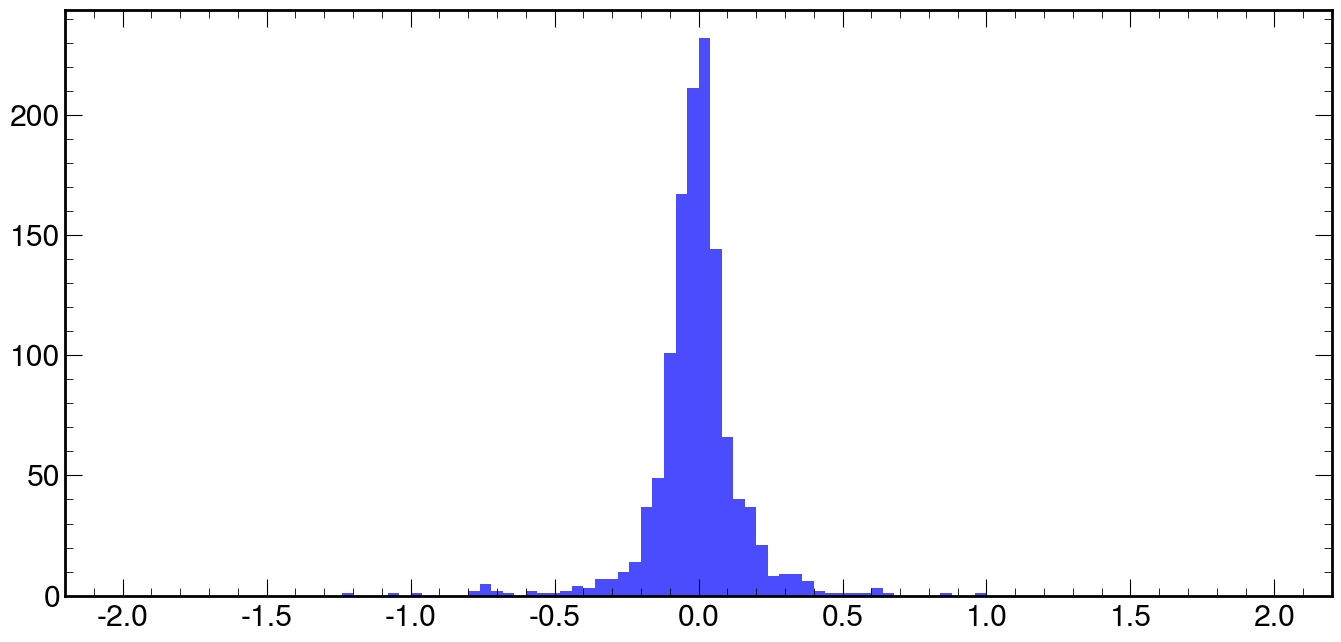

In [51]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
#plt.yscale("log")

x_range=(-2,2)
ax.hist(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["true_PV_z"] - df_groups_info[(df_groups_info["n_true_PVs"]==1)]["mz"]), bins=n_bins, range=x_range, color=d_colors[1], alpha=0.7)
np.mean(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["true_PV_z"] - df_groups_info[(df_groups_info["n_true_PVs"]==1)]["mz"]))

In [44]:
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==0)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==1)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==2)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==3)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==4)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==5)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==6)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==7)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==8)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==9)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==10)]))
print(len(df_groups_info[(df_groups_info["n_true_PVs"]==11)]))


27
1215
380
149
61
27
5
5
2
0
0
0


In [45]:
df_groups_info[(df_groups_info["n_true_PVs"]==0)]


,iEvt,n_true_PVs,true_PV_z,true_PV_sz,S,mz,sz,vz,dz,n,sz/vz,sz/dz,dz/vz
71,19,0,-999.0,-999.0,False,-44.660340,0.110569,2.700255e-01,8.072392,4,0.409478,0.013697,2.989492e+01
86,23,0,-999.0,-999.0,True,-105.437329,0.180130,6.791635e-02,0.953384,6,2.652235,0.188938,1.403763e+01
125,35,0,-999.0,-999.0,False,32.779070,0.170420,4.606399e-01,7.410309,6,0.369964,0.022998,1.608699e+01
286,82,0,-999.0,-999.0,True,-70.254696,0.316568,2.776299e-02,6.013618,7,11.402515,0.052642,2.166056e+02
401,110,0,-999.0,-999.0,False,1.942695,0.079762,8.394064e-06,0.955883,4,9502.223241,0.083444,1.138761e+05
446,123,0,-999.0,-999.0,False,-68.214720,3.393004,2.562008e-01,1.602310,4,13.243534,2.117570,6.254119e+00
518,144,0,-999.0,-999.0,False,116.790960,5.119283,1.496593e+00,3.085556,4,3.420625,1.659112,2.061721e+00
539,150,0,-999.0,-999.0,True,-56.280809,0.130608,9.943177e-02,3.516521,6,1.313548,0.037141,3.536618e+01
556,154,0,-999.0,-999.0,True,-102.802343,0.133084,4.279766e-02,1.437576,8,3.109600,0.092575,3.359007e+01
596,164,0,-999.0,-999.0,False,102.296356,2.125890,1.025060e-02,1.078026,4,207.391747,1.972021,1.051671e+02


In [46]:

print(len(df_groups_info[(df_groups_info["sz"]>0.5) & (df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)])/len(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]))
print(len(df_groups_info[(df_groups_info["sz"]>0.5) & (df_groups_info["n_true_PVs"]==1)])/len(df_groups_info[(df_groups_info["n_true_PVs"]==1)]))


0.4375
0.0016460905349794238


In [47]:
len(df_groups_info[(df_groups_info["n_true_PVs"]==1) & (df_groups_info["sz"]*df_groups_info["dz"]>2.0)])/len(df_groups_info[(df_groups_info["n_true_PVs"]==1)])



0.0016460905349794238

(array([9., 2., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([  0.,   5.,  10.,  15.,  20.,  25.,  30.,  35.,  40.,  45.,  50.,
         55.,  60.,  65.,  70.,  75.,  80.,  85.,  90.,  95., 100., 105.,
        110., 115., 120., 125., 130., 135., 140., 145., 150., 155., 160.,
        165., 170., 175., 180., 185., 190., 195., 200., 205., 210., 215.,
        220., 225., 230., 235., 240., 245., 250., 255., 260., 265., 270.,
        275., 280., 285., 290., 295., 300., 305., 310., 315., 320., 325.,
        330., 335., 340., 345., 350., 355., 360., 365., 370., 375., 380.,
        385., 390., 395., 400., 

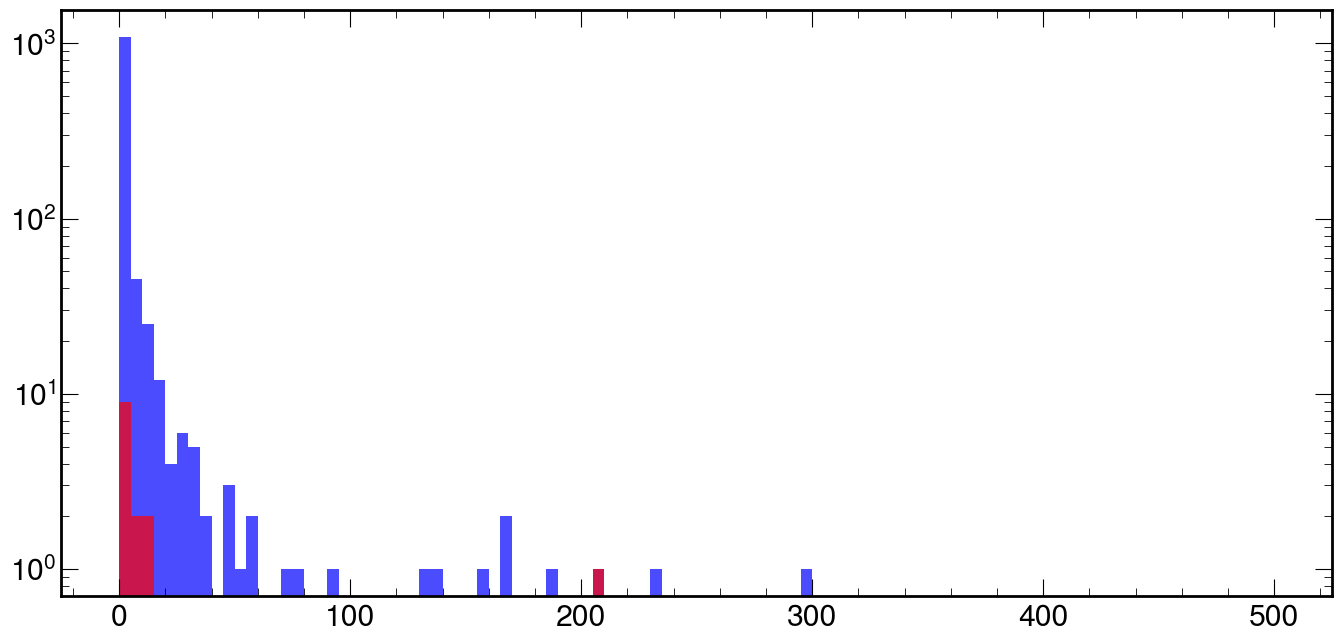

In [36]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
plt.yscale("log")

x_range=(0,500)
ax.hist(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["sz"] / df_groups_info[(df_groups_info["n_true_PVs"]==1)]["vz"]), bins=n_bins, range=x_range, color=d_colors[1], alpha=0.7)
ax.hist(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["sz"] / df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["vz"]), bins=n_bins, range=x_range, color=d_colors[0], alpha=0.7)


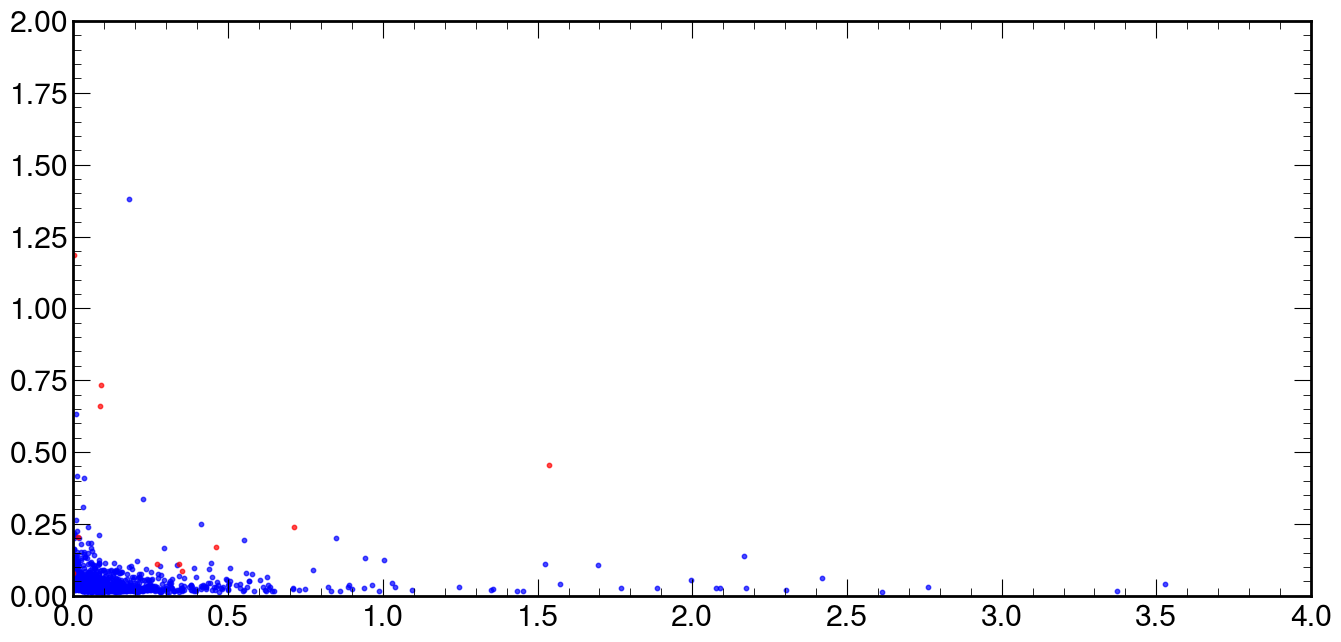

In [67]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,4)
plt.ylim(0,2)
#for i in range(5):
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["vz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["sz"]), s=10, marker="o", c=d_colors[1], alpha=0.7)
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["vz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["sz"]), s=10, marker="o", c=d_colors[0], alpha=0.7)


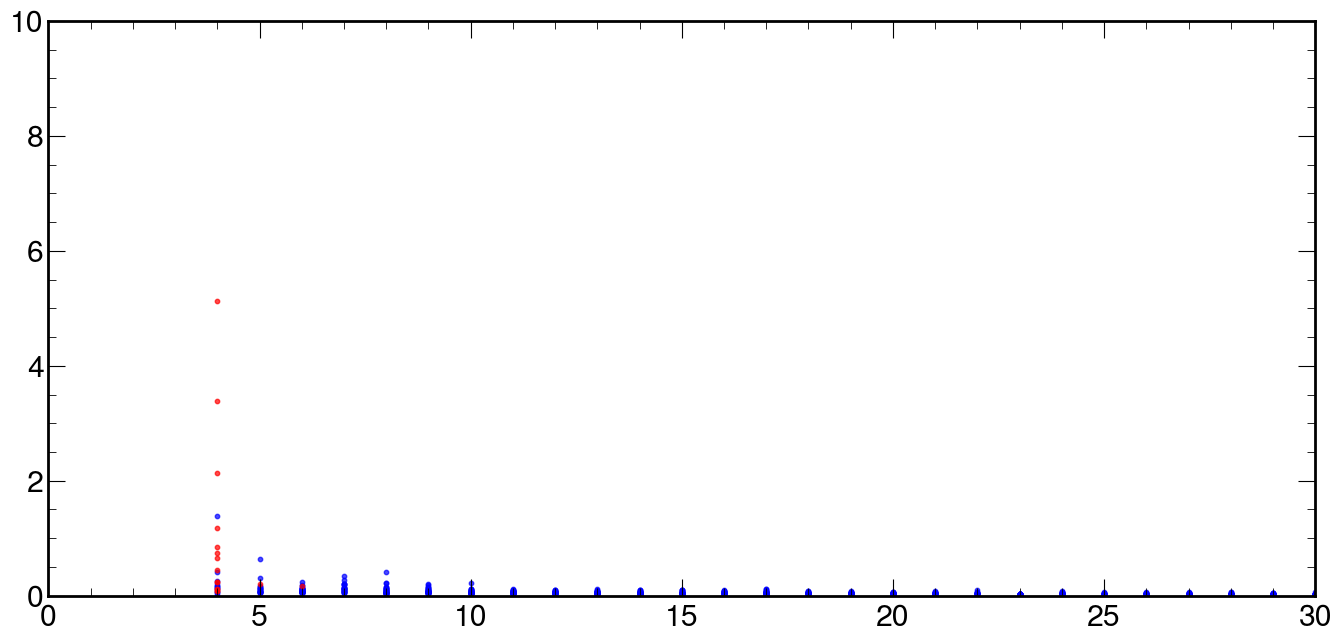

In [68]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,30)
plt.ylim(0,10)
#for i in range(5):
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["n"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["sz"]), s=10, marker="o", c=d_colors[1], alpha=0.7)
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["n"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["sz"]), s=10, marker="o", c=d_colors[0], alpha=0.7)


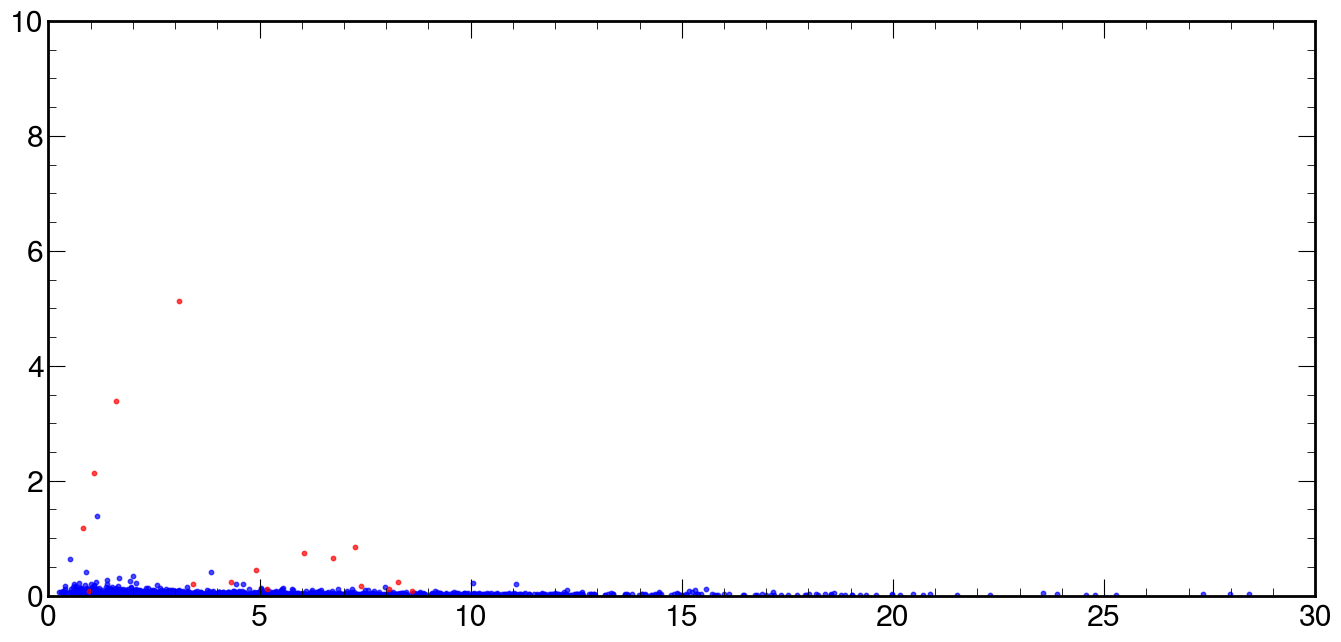

In [69]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,30)
plt.ylim(0,10)
#for i in range(5):
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["dz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["sz"]), s=10, marker="o", c=d_colors[1], alpha=0.7)
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["dz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0) & (df_groups_info["S"]==0)]["sz"]), s=10, marker="o", c=d_colors[0], alpha=0.7)


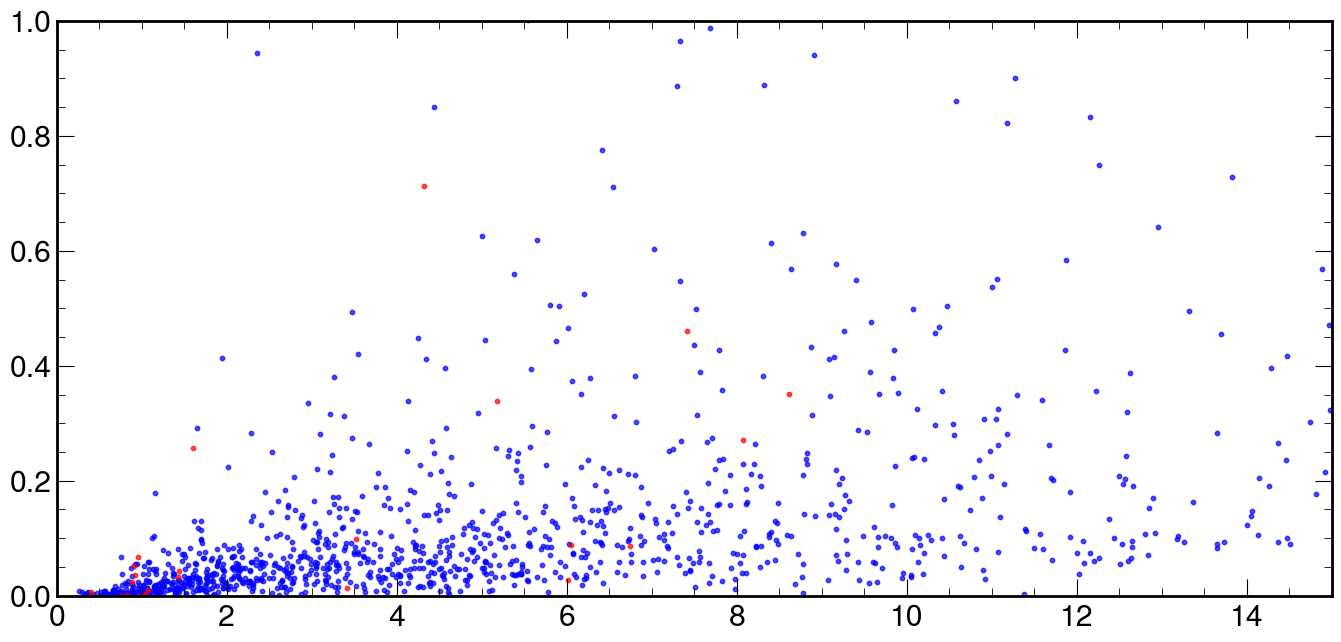

In [70]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,15)
plt.ylim(0,1)
#for i in range(5):
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["dz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==1)]["vz"]), s=10, marker="o", c=d_colors[1], alpha=0.7)
ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0)]["dz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==0)]["vz"]), s=10, marker="o", c=d_colors[0], alpha=0.7)


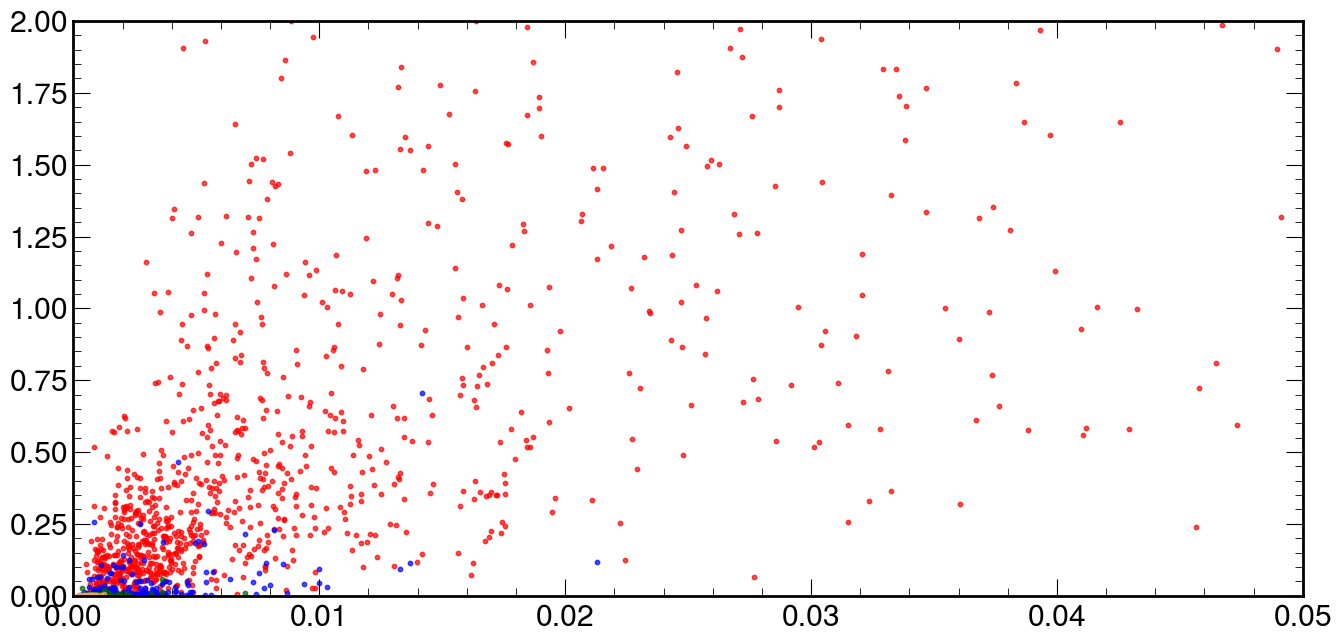

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,0.05)
plt.ylim(0,2.0)
for i in range(1,5):
    ax.scatter(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==i)]["sz/dz"]), np.array(df_groups_info[(df_groups_info["n_true_PVs"]==i)]["sz/vz"]), s=10, marker="o", c=d_colors[i-1], alpha=0.7)


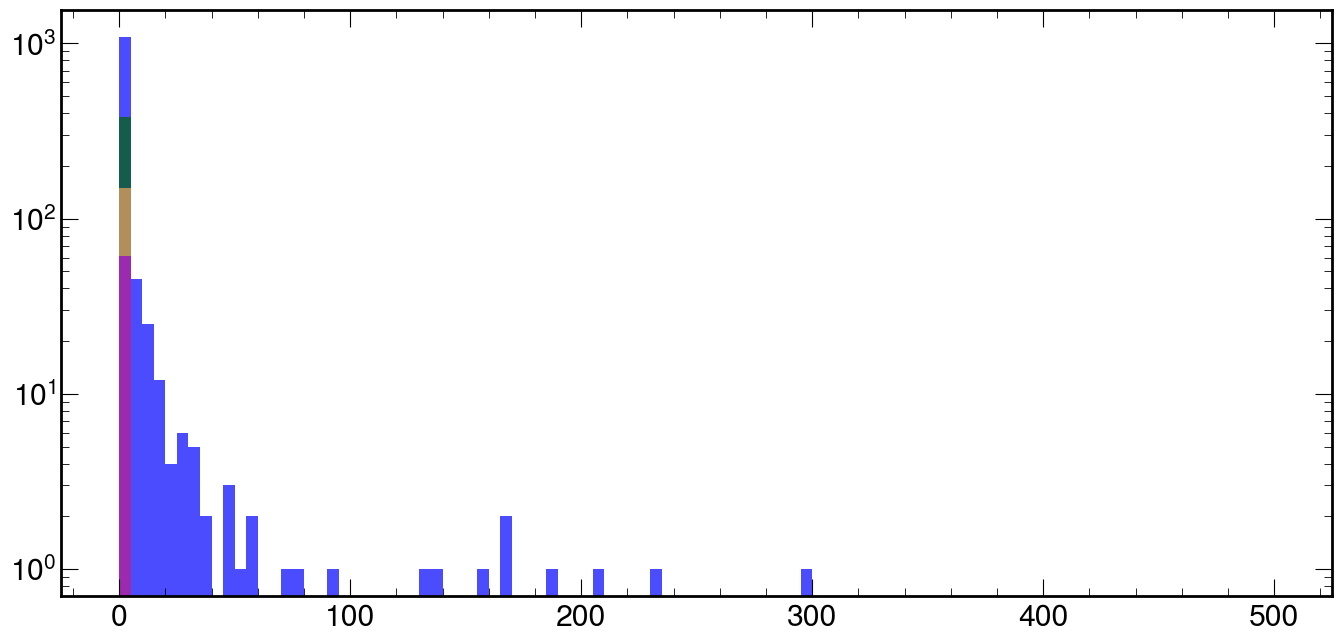

In [72]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
plt.yscale("log")

x_range=(0,500)
for i in range(1,5):
    ax.hist(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==i)]["sz/vz"]), bins=n_bins, range=x_range, color=d_colors[i], alpha=0.7)


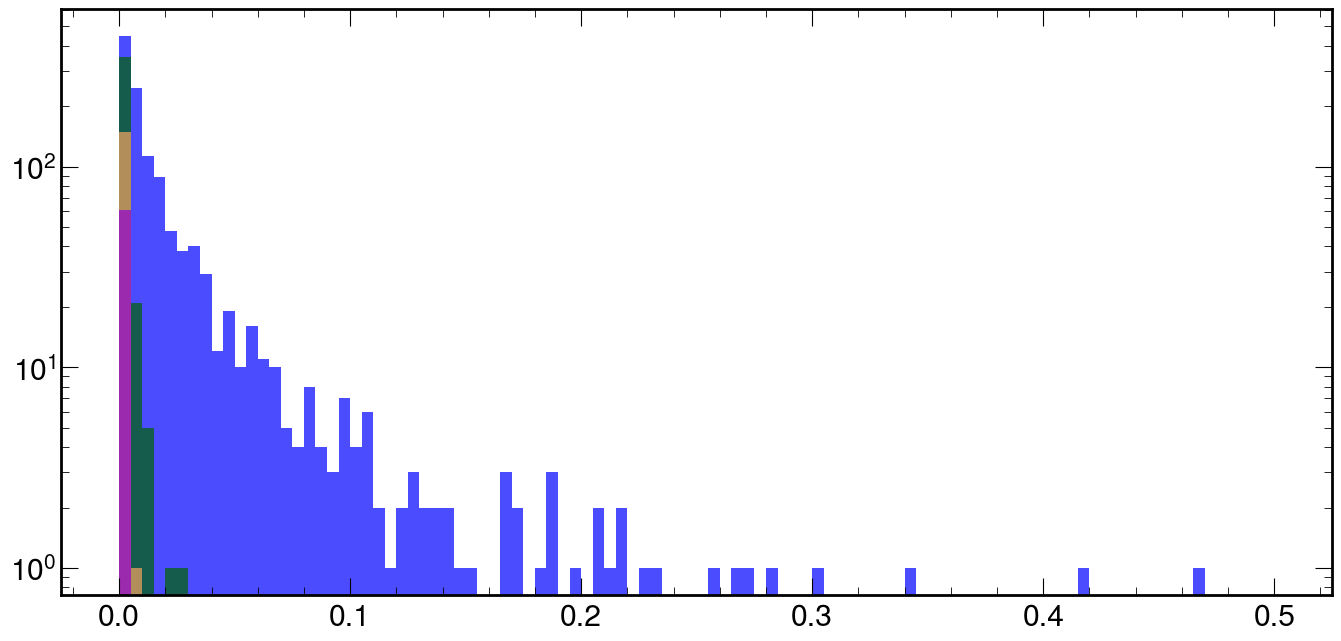

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
plt.yscale("log")

x_range=(0,0.5)
for i in range(1,5):
    ax.hist(np.array(df_groups_info[(df_groups_info["n_true_PVs"]==i)]["sz/dz"]), bins=n_bins, range=x_range, color=d_colors[i], alpha=0.7)


In [74]:
for key in d_evts_group_nopv.keys():
    if d_evts_group_nopv[key]["sz"]>d_evts_group_nopv[key]["dz"]:
        print("False FP?")
        print(key)
        print(d_evts_group_nopv[key])
        

NameError: name 'd_evts_group_nopv' is not defined

In [ ]:
for i in range(len(d_groups_info_evts[0]["sz"])):
    print("----------------")
    print("sz = %.3f"%d_groups_info_evts[0]["sz"][i])
    print("dz = %.3f"%d_groups_info_evts[0]["dz"][i])

In [ ]:
np.array(d_groups_info_evts[2]["sz"])/np.array(d_groups_info_evts[2]["vz"])>0.3

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
plt.yscale("log")

x_range=(0,100)
ax.hist(np.array(d_groups_info_evts[1]["sz/dz"]), bins=n_bins, range=x_range, color=d_colors[1], alpha=0.7)
for i in range(2,5):
    ax.hist(np.array(d_groups_info_evts[i]["sz/dz"]), bins=n_bins, range=x_range, color=d_colors[i], alpha=0.7)


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
#plt.yscale("log")
x_range=(0,1000)
ax.hist(np.array(d_groups_info_evts[1]["dz"])/np.array(d_groups_info_evts[1]["vz"]), bins=n_bins, range=x_range, color=d_colors[1], alpha=0.7)
ax.hist(np.array(d_groups_info_evts[0]["dz"])/np.array(d_groups_info_evts[0]["vz"]), bins=n_bins, range=x_range, color=d_colors[0], alpha=0.7)
for i in range(2,5):
    ax.hist(np.array(d_groups_info_evts[i]["dz"])/np.array(d_groups_info_evts[i]["vz"]), bins=n_bins, range=x_range, color=d_colors[i], alpha=0.7)


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
plt.yscale("log")

x_range=(0,20)
ax.hist(np.array(d_groups_info_evts[1]["sz"])/np.array(d_groups_info_evts[1]["dz"]), bins=n_bins, range=x_range, color=d_colors[1], alpha=0.7)
ax.hist(np.array(d_groups_info_evts[0]["sz"])/np.array(d_groups_info_evts[0]["dz"]), bins=n_bins, range=x_range, color=d_colors[0], alpha=0.7)
for i in range(2,5):
    ax.hist(np.array(d_groups_info_evts[i]["sz"])/np.array(d_groups_info_evts[i]["dz"]), bins=n_bins, range=x_range, color=d_colors[i], alpha=0.7)


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
plt.xlim(0,25)
plt.ylim(0,0.1)
for i in range(5):
    ax.scatter(np.array(d_groups_info_evts[i]["dz"])/np.array(d_groups_info_evts[i]["vz"]), np.array(d_groups_info_evts[i]["sz"])/np.array(d_groups_info_evts[i]["vz"]), s=10, marker="o", c=d_colors[i], alpha=0.7)
#ax.scatter(np.array(d_groups_info_evts[1]["dz"])/np.array(d_groups_info_evts[1]["vz"]), np.array(d_groups_info_evts[1]["sz"])/np.array(d_groups_info_evts[1]["vz"]), s=10, marker="o", c=d_colors[1], alpha=1.0)
#ax.scatter(np.array(d_groups_info_evts[2]["dz"])/np.array(d_groups_info_evts[2]["vz"]), np.array(d_groups_info_evts[2]["sz"])/np.array(d_groups_info_evts[2]["vz"]), s=10, marker="o", c=d_colors[2], alpha=1.0)
#ax.scatter(np.array(d_groups_info_evts[2]["dz"])/np.array(d_groups_info_evts[2]["vz"]), np.array(d_groups_info_evts[2]["sz"])/np.array(d_groups_info_evts[2]["vz"]), s=10, marker="o", c=d_colors[2], alpha=1.0)

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), sharey=False, tight_layout=True)
n_bins = 100
tracks_z_sigma_arr = ak.to_numpy(poca_sigma_z[0])
print(len(poca_sigma_z[0]))
for iEvt in range(1,2):
    print(len(poca_sigma_z[iEvt]))
    tracks_z_sigma_arr = np.append(tracks_z_sigma_arr,poca_sigma_z[iEvt], axis=0)
ax.hist(tracks_z_sigma_arr, bins=n_bins, range=(0,10))
len(tracks_z_sigma_arr[tracks_z_sigma_arr>5])/float(len(tracks_z_sigma_arr))


In [ ]:
def get_wz(z,sz):
    w_z = np.power(sz,-2)
    sum_w_z = np.sum(w_z)
    mu_z = np.sum(w_z * z)/sum_w_z
    s_z = 1./np.sqrt(sum_w_z)
    return mu_z, s_z

z_all=[16.53615761, 16.61736679, 17.37752724, 17.54581642, 17.6727562, 17.72361755,
 18.07016182, 18.24913216, 18.30915451, 18.49760818, 18.52267075, 18.60041618,
 18.82942581, 18.87338638, 19.05770493, 19.60832977, 19.67589378, 20.04517937,
 20.05356598, 27.31522751, 27.44485283]
sz_all=[0.17324305, 0.26295319, 0.67789443, 0.24376631, 1.27233395, 0.70703061,
 0.10440004, 0.35525527, 0.48507868, 0.0928546,  0.2558464,  0.19414497,
 0.13252579, 0.21699046, 0.1191542,  0.43942422, 0.16927192, 0.79682896,
 0.25956307, 0.38171472, 0.07605253]


print("%.2f +/- %.2f"%(get_wz(z_all,sz_all)))
print("%.2f +/- %.2f"%(get_wz(z_all[:-1],sz_all[:-1])))
print("%.2f +/- %.2f"%(get_wz(z_all[1:],sz_all[1:])))
print("%.2f +/- %.2f"%(get_wz(z_all[1:-1],sz_all[1:-1])))
print("%.2f +/- %.2f"%(get_wz(z_all[1:-2],sz_all[1:-2])))
print("%.2f +/- %.2f"%(get_wz(z_all[2:-1],sz_all[2:-1])))
print("%.2f +/- %.2f"%(get_wz(z_all[2:-2],sz_all[2:-2])))

abs(20.72-18.58)/0.04

In [ ]:
z_all=[1, 4, 7, 9]
sz_all=[1.0, 1.0, 1.0, 1.0]
print("%.2f +/- %.2f"%(get_wz(z_all,sz_all)))
print("%.2f +/- %.2f"%(get_wz(z_all[:-1],sz_all[:-1])))
print("%.2f +/- %.2f"%(get_wz(z_all[1:],sz_all[1:])))
abs(5.25-4.00)/0.5

In [ ]:

m_sp_adj = get_sp_adj(ak.to_numpy(poca_x[iEvt]),ak.to_numpy(poca_y[iEvt]),ak.to_numpy(poca_z[iEvt]),1000)
m_sp_adj


In [ ]:
tracks_pvs_link = _connected_components_cpu_np(m_sp_adj[0],431)
tracks_pvs_link

In [ ]:
tracks_pvs_link["pvs"].unique()

In [ ]:
mult_tracks_pvs_link_idx = tracks_pvs_link.sort_index().groupby('pvs').filter(lambda group: len(group) > 1)["tracks"].tolist()
mult_tracks_pvs_link_idx

In [ ]:
mult_tracks_pvs_link = tracks_pvs_link["pvs"][mult_tracks_pvs_link_idx].tolist()
mult_tracks_pvs_link

In [ ]:
list_mult_tracks_pvs_id = tracks_pvs_link["pvs"][mult_tracks_pvs_link_idx].unique()
list_mult_tracks_pvs_id

In [ ]:
tracks_pvs_link.sort_index().groupby('pvs').filter(lambda group: len(group) == 1)["tracks"].tolist()

In [ ]:
d_tracks_pvs_link = {}
d_tracks_pvs_link[-1] = tracks_pvs_link.sort_index().groupby('pvs').filter(lambda group: len(group) == 1)["tracks"].tolist()
for i in range(len(list_mult_tracks_pvs_id)):
    d_tracks_pvs_link[i] = tracks_pvs_link["tracks"][tracks_pvs_link["pvs"]==list_mult_tracks_pvs_id[i]].tolist()

In [ ]:
d_tracks_pvs_link

In [ ]:
arr = ak.to_numpy(poca_z[iEvt])
for key in d_tracks_pvs_link.keys():
    print(arr[d_tracks_pvs_link[key]])

In [ ]:
iso_tracks_pvs_link_idx = tracks_pvs_link.sort_index().groupby('pvs').filter(lambda group: len(group) == 1)["tracks"].tolist()
iso_tracks_pvs_link_idx

In [ ]:
iso_tracks_pvs_val = tracks_pvs_link["pvs"][iso_tracks_pvs_link_idx].tolist()
iso_tracks_pvs_val

In [ ]:
tracks_pvs_link["pvs"] = tracks_pvs_link["pvs"].replace(iso_tracks_pvs_val, -1).tolist()
tracks_pvs_link

In [ ]:
first_pv_id = tracks_pvs_link["pvs"][tracks_pvs_link["pvs"]>-1].tolist()[0]
first_pv_id

In [ ]:
list(map(lambda x: x - first_pv_id, mult_tracks_pvs_link))

In [ ]:
coords = np.column_stack((np.array([1.5,2.1,3.3,4.7,5.2]),np.array([1.5,2.3,3.7,4.9,5.5]),np.array([1.6,2.0,3.3,4.3,5.3])))

In [ ]:
dist = cdist(coords, coords)
dist

In [ ]:
dist[1:4,1:4]

In [ ]:
coords = np.column_stack((ak.to_numpy(poca_x[iEvt]),ak.to_numpy(poca_y[iEvt]),ak.to_numpy(poca_z[iEvt])))

In [ ]:
coords.shape

In [ ]:
dist = cdist(coords, coords)
dist

In [ ]:
dist_filt_ones = np.where(dist < 10, 1, 0)
dist_filt_ones[]

In [ ]:
adj = torch.tensor(dist_filt_ones)
sp = dense_to_sparse(adj)
sp[0]

In [ ]:
edge_index = torch.tensor([[0, 0, 0, 1, 2, 3, 4],
                           [0, 1, 2, 0, 0, 4, 3]])
edge_index

In [ ]:
np.ones(edge_index.shape[0])

In [ ]:
edge_index[0]

In [ ]:
import scipy.sparse as sps
sps.coo_matrix((np.ones(edge_index[0].shape),(edge_index[0], edge_index[1]),),(4 + 1, 4 + 1),)


In [ ]:
cc_test = _connected_components_cpu_np(edge_index, 4)
cc_test.groupby("labels")["vertex"]
cc_test["labels"]

In [ ]:
adj = to_torch_coo_tensor(edge_index)
adj
to_edge_index(adj)

In [ ]:
for i in range(75604):
    print(sp[0][0][i])
    
len(sp[0][0])

In [ ]:
len(sp[0][0])

In [ ]:
print(dist[0])
print(dist[1])


In [ ]:
f=1./(dist)

In [ ]:
f

In [ ]:
id = np.eye(f.shape[0])*1000000

In [ ]:
id

In [ ]:
f = f-id+np.eye(f.shape[0])

In [ ]:
f

In [ ]:
f_n = normalize(f, axis=1, norm='l2')
dist_n = normalize(dist, axis=1, norm='max')

In [ ]:
s_dist_n = sum(dist_n)
s_dist_n

In [ ]:
for iTrack in range(len(poca_z[iEvt])):
    print("Track[%s]: z = %.2f \t pv_ass = %s \t sum(d) = %.1f "%(iTrack, poca_z[iEvt][iTrack], recon_pv_key[iEvt][iTrack], s_dist_n[iTrack]))

In [ ]:
#plt.scatter(poca_z[iEvt][poca_z[iEvt]>-100],dist_n[130][poca_z[iEvt]>-100])
plt.scatter(dist_n[100][poca_z[iEvt]>-100],dist_n[0][poca_z[iEvt]>-100])


In [ ]:
f[10]

In [ ]:
f_n[1]

In [ ]:
f_n[10]>0.4

In [ ]:
dist_n

In [ ]:
p=((1./(cdist(coords, coords)+np.eye(f.shape[0])))-np.eye(f.shape[0]))

In [ ]:
p_n_max = normalize(p, axis=1, norm='max')
p_n_l2 = normalize(p, axis=1, norm='l2')
p_n_l1 = normalize(p, axis=1, norm='l1')
sum(p_n_l1)

In [ ]:
for iTrack in range(len(poca_z[iEvt])):
    print("Track[%s]: z = %.2f \t pv_ass = %s \t sum(d) = %.1f "%(iTrack, poca_z[iEvt][iTrack], recon_pv_key[iEvt][iTrack], sum(p_n_l1)[iTrack]))

In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(p_n_max)
#plt.matshow(f)
plt.colorbar(im, ax=ax)
plt.show()


In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(p_n_l2)
#plt.matshow(f)
plt.colorbar(im, ax=ax)
plt.show()


In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(p_n_l1)
#plt.matshow(f)
plt.colorbar(im, ax=ax)
plt.show()


In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(1./dist-1000000.0*np.eye(f.shape[0]))
#im = ax.imshow(normalize(1./dist-np.eye(f.shape[0]), axis=1, norm="l1"))
#plt.matshow(f)
plt.colorbar(im, ax=ax)
plt.show()


In [ ]:
dist
l = dist.shape[0]
arr = np.zeros(l)
arr[l-1]

In [ ]:
def aggregate(m_dist):
    l = m_dist.shape[0]
    arr = np.zeros(l)
    for i in range(l):
        if i<5:
            arr[i] = sum(dist[0][0:i+4])
        elif i>=5 and i<=l-5:
            arr[i] = sum(dist[0][i-4:i+4])
        else:
            arr[i] = sum(dist[0][i-4:l-1])
            
    return arr

In [ ]:
r = aggregate(dist)

In [ ]:
delta_d = np.zeros(l-1)
    
for i in range(l-1):
    delta_d[i] = np.power(dist[0][i+1]-dist[0][i],2)

In [ ]:
delta_d_agg = aggregate(delta_d) 

In [ ]:
filt1=1./delta_d<1000000
filt2 = poca_z[iEvt][:l-1]>100
filt3 = poca_z[iEvt][:l-1]<200
filt = filt1 & filt2 & filt3

In [ ]:
n_bins = 10000
plt.hist(poca_z[iEvt][:l-1][filt], bins=n_bins, weights=1./delta_d[filt])
plt.show()

In [ ]:
poca_z[iEvt][:l-1][1./delta_d>100]

In [ ]:
#n_bins = 1000
#plt.hist(poca_z[iEvt][:l-1][filt], bins=n_bins, weights=1./delta_d_agg[filt])
#plt.show()

In [ ]:
iEvt=0
plot_tracks_polar(iEvt, 
                  pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], 
                  poca_x[iEvt], poca_sigma_x[iEvt], 
                  poca_y[iEvt], poca_sigma_y[iEvt], 
                  poca_z[iEvt], poca_sigma_z[iEvt], 
                  recon_tx[iEvt], recon_ty[iEvt], 
                  recon_pv_key[iEvt], 
                  'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', 
                  doFilt=False)
plot_tracks_polar(iEvt, pv_x[iEvt], pv_y[iEvt], pv_z[iEvt], pv_n[iEvt], pv_key[iEvt], poca_x[iEvt], poca_sigma_x[iEvt], poca_y[iEvt], poca_sigma_y[iEvt], poca_z[iEvt], poca_sigma_z[iEvt], recon_tx[iEvt], recon_ty[iEvt], recon_pv_key[iEvt], 'pv_HLT1CPU_MinBiasMagUp_1__validPVs_2tracks', doFilt=True, min_d_tracks=0.3, min_d_pv=5.0)  
